In [1]:
!pip install -q gensim

# **Opis skupa podataka**





MIND je veliki skup podataka koji je javno dostupan od strane Microsoft kompanije koji služi za istraživanje preporuka vijesti. Skup podataka je prikupljen s Microsoftovih web stranica s vijestima. MIND sadrži oko 160 tisuća engleskih novinskih članaka i više od 15 milijuna zapisa o interakcija koje generira 1 milijun korisnika. Iz tog razloga je za projektni dio zadatka uzet u obzir MIND-small. Riječ je o manjem skupu podataka nastao slučajnim uzorkovanjem originalnog velikog MIND skupa. MIND-small sadrži 50 000 korisnika i zapise njihovog ponašanja. Mind-small prvobitno sadrži samo skupove za obuku i validaciju.


In [2]:
from google.colab import drive

drive.mount('/content/drive/')

Mounted at /content/drive/


In [3]:
!unzip -q /content/drive/MyDrive/MIND.zip -d /content/MIND

!find /content/MIND -maxdepth 3

/content/MIND
/content/MIND/MINDsmall_train
/content/MIND/MINDsmall_train/entity_embedding.vec
/content/MIND/MINDsmall_train/relation_embedding.vec
/content/MIND/MINDsmall_train/news.tsv
/content/MIND/MINDsmall_train/behaviors.tsv
/content/MIND/news.tsv
/content/MIND/news.tsv/news.tsv


Skup podataka MIND-small je preuzet s Kaggle repozitorija te raspakiran
na disk od Google Colaba.

Skup podataka se nalazi u mapi MINDsmall_train koja sadrži datoteke
behaviors.tsv, news.tsv, relation_embedding.vec i entity_embedding.vec.

U radu su korištene prve dvije datoteke iz razloga što relation_embedding.vec i entity_embedding.vec su pretrenirani emebednig entiteti iz cijelog MIND skupa te nisu nisu uključeni jer usporedba u radu obuhvaća reprezentacije dobivene iz teksta članaka.

In [4]:
from pathlib import Path
data_dir = Path('/content/MIND/MINDsmall_train')
news_path = data_dir / 'news.tsv'
behaviors_path = data_dir / 'behaviors.tsv'


In [5]:
#Analiza podataka

In [6]:
import pandas as pd

behaviors_cols = ["ImpressionID", "UserID", "Time", "History", "Impressions"]
behaviors = pd.read_csv(behaviors_path, sep="\t", names=behaviors_cols)

news_cols = ["NewsID", "Category", "SubCategory", "Title", "Abstract",
             "URL", "TitleEntities", "AbstractEntities"]
news = pd.read_csv(news_path, sep="\t", names=news_cols)

print("behaviors:", behaviors.shape)
print("news:", news.shape)

behaviors: (156965, 5)
news: (51282, 8)


In [7]:
news.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51282 entries, 0 to 51281
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   NewsID            51282 non-null  object
 1   Category          51282 non-null  object
 2   SubCategory       51282 non-null  object
 3   Title             51282 non-null  object
 4   Abstract          48616 non-null  object
 5   URL               51282 non-null  object
 6   TitleEntities     51279 non-null  object
 7   AbstractEntities  51278 non-null  object
dtypes: object(8)
memory usage: 3.1+ MB


In [8]:
news.head()

,NewsID,Category,SubCategory,Title,Abstract,URL,TitleEntities,AbstractEntities
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[]
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik..."
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId..."
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi...",https://assets.msn.com/labs/mind/AACk2N6.html,[],"[{""Label"": ""National Basketball Association"", ..."
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re...",https://assets.msn.com/labs/mind/AAAKEkt.html,"[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI...","[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI..."


Datoteka `News.tsv` sadrži sljedeće atribute:

| Atribut | Opis |
|---|---|
| `NewsID` | jedinstveni identifikator članka koristi se za povezivanje s datotekom behaviors.tsv |
| `Category` | glavna kategorija članka |
| `SubCategory` | podkategorija unutar glavne kategorije |
| `Title` | naslov članka |
| `Abstract` | kratki sažetak članka |
| `URL` | web adresa izvornog članka |
| `TitleEntities` | popis entiteta izvučenih iz naslova |
| `AbstractEntities` | popis entiteta izvučenih iz sažetka |

Za potrebe rada koriste se atributi NewsID, Category, Title i Abstract.
NewsID koristi se za povezivanje podataka, Category za analizu kategorija, filtriranje kandidata i oznake pri logističkoj regresiji, a Title i Abstract za generiranje vektorskih reprezentacija.







In [9]:
behaviors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156965 entries, 0 to 156964
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   ImpressionID  156965 non-null  int64 
 1   UserID        156965 non-null  object
 2   Time          156965 non-null  object
 3   History       153727 non-null  object
 4   Impressions   156965 non-null  object
dtypes: int64(1), object(4)
memory usage: 6.0+ MB


In [10]:
behaviors.head()

,ImpressionID,UserID,Time,History,Impressions
0,1,U13740,11/11/2019 9:05:58 AM,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0
1,2,U91836,11/12/2019 6:11:30 PM,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...
2,3,U73700,11/14/2019 7:01:48 AM,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,N50014-0 N23877-0 N35389-0 N49712-0 N16844-0 N...
3,4,U34670,11/11/2019 5:28:05 AM,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,N35729-0 N33632-0 N49685-1 N27581-0
4,5,U8125,11/12/2019 4:11:21 PM,N10078 N56514 N14904 N33740,N39985-0 N36050-0 N16096-0 N8400-1 N22407-0 N6...


Datoteka behaviors.tsv sadrži zapise o interakcijama korisnika s člancima. Svaki redak predstavlja jednu impresiju u kojoj je korisniku ponuđen skup članaka.
Datoteka sadrži sljedeće atribute:

| Atribut | Opis |
|---|---|
|`ImpressionID`| jedinstveni indentifikator impresije |
| `UserID ` | jedinstveni indentifikator korisnika |
| `Time` | vrijeme nastanka impresije |
| `History` | popis članaka koje je korisnik prethodno kliknuo |
| `Impressions` | popis članaka ponuđenih u toj impresiji s oznakom je li pojedini članak kliknut (`1`) ili nije (`0`)|



In [11]:

news_clean = news[["NewsID", "Category", "SubCategory", "Title", "Abstract"]].copy()

print("Originalni news:", news.shape)
print("Očišćeni news_clean:", news_clean.shape)

Originalni news: (51282, 8)
Očišćeni news_clean: (51282, 5)


In [12]:
print("NEDOSTAJUĆE VRIJEDNOSTI — news_clean\n")

print(news_clean.isna().sum())
print("\nPostotak:")
print((news_clean.isna().sum() / len(news_clean) * 100).round(2))

NEDOSTAJUĆE VRIJEDNOSTI — news_clean

NewsID            0
Category          0
SubCategory       0
Title             0
Abstract       2666
dtype: int64

Postotak:
NewsID         0.0
Category       0.0
SubCategory    0.0
Title          0.0
Abstract       5.2
dtype: float64


U skupu s vijestima jedini je `Abstract` koji ima nedostajuće vrijednosti. Od ukupno 51.282 članka u katalogu njih 2666 (5,2%) nema popunjeno polje `Abstract`

In [13]:
prazni = news_clean.groupby("Category")["Abstract"].apply(lambda x: x.isna().sum())
print((prazni / news_clean.groupby("Category").size() * 100).round(2).sort_values(ascending=False))

Category
sports           8.81
autos            8.36
weather          8.25
lifestyle        6.45
kids             5.88
travel           5.40
entertainment    5.28
news             3.62
health           2.71
tv               2.36
music            1.95
finance          1.90
foodanddrink     1.49
movies           0.66
video            0.15
middleeast       0.00
northamerica     0.00
dtype: float64


Udio nedostajućih sažetaka se kreće od 0.15% do 8.81%.
Kako nema izražene koncentracije kod nedostajućih sažetaka po kategorijama članci bez sažetka nisu izostavljeni iz skupa.

In [14]:
print("NEDOSTAJUĆE VRIJEDNOSTI - behaviors\n")

print(behaviors.isna().sum())
print("\nPostotak:")
print((behaviors.isna().sum() / len(behaviors) * 100).round(2))

NEDOSTAJUĆE VRIJEDNOSTI - behaviors

ImpressionID       0
UserID             0
Time               0
History         3238
Impressions        0
dtype: int64

Postotak:
ImpressionID    0.00
UserID          0.00
Time            0.00
History         2.06
Impressions     0.00
dtype: float64


Od 156965 impresija njih 3238 (2.06%) nema popunjeno polje `History`. Prazan History označava korisnike bez zabilježeni povijesti klikova prije te impresije.

In [15]:


is_empty_history = behaviors["History"].isna() | (behaviors["History"].fillna("").str.strip() == "")

cold_user_ids = set(behaviors["UserID"]) - set(behaviors.loc[~is_empty_history, "UserID"])
broj_cold_korisnika = len(cold_user_ids)
ukupno_korisnika = behaviors["UserID"].nunique()

print("Cold-start korisnika (PO KORISNIKU, sve impresije prazne):")
print(f"  {broj_cold_korisnika} od {ukupno_korisnika} ({broj_cold_korisnika/ukupno_korisnika*100:.2f}%)")



Cold-start korisnika (PO KORISNIKU, sve impresije prazne):
  892 od 50000 (1.78%)


Od ukupno 50.000 korisnika njih 892, odnosno 1,78 %, ima prazan History u svim svojim impresijama.

In [16]:
print("Ukupan broj korisnika:")
print(behaviors["UserID"].nunique())

impresije_per_user = behaviors.groupby("UserID").size()

print("\nBroj impresija po korisniku:")
print(impresije_per_user.describe())

print("\nBroj korisnika po broju impresija:")
print(impresije_per_user.value_counts().sort_index().head(10))

Ukupan broj korisnika:
50000

Broj impresija po korisniku:
count    50000.000000
mean         3.139300
std          3.001026
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         62.000000
dtype: float64

Broj korisnika po broju impresija:
1     16383
2     11867
3      7490
4      4535
5      2808
6      1987
7      1305
8       897
9       666
10      500
Name: count, dtype: int64


In [17]:
print(impresije_per_user.quantile([0.90, 0.95, 0.99]))

0.90     6.0
0.95     9.0
0.99    15.0
dtype: float64


Skup podataka sadrži 50000 korisnika te svaki korisnik ima barem jednu impresiju. Medijan je 2 impresije, prosjek je 3,14 a maksimum je 62 impresije. Razlika između medijana i prosjeka ukazuje na to da većinu čine korisnici s manjim brojem impresija a prosjek dižu rijetki aktivni korisnici. Kvartili pokazuju da 25% korisnika ima najviše 1 impresiju, 50 % ima najviše 2 impresije a 75% ima najviše 4. Broj korisnika opada s povećanjem broja impresija. Trećina korisnika ima jednu impresiju a gotovo 60 posto ima najviše 2.

In [18]:
behaviors["Time"] = pd.to_datetime(behaviors["Time"], format="%m/%d/%Y %I:%M:%S %p")


In [19]:
print("Raspon vremena:")
print(behaviors["Time"].min())
print(behaviors["Time"].max())

print("\nBroj impresija po danu:")
print(behaviors["Time"].dt.date.value_counts().sort_index())

print("\nBroj impresija po satu:")
print(behaviors["Time"].dt.hour.value_counts().sort_index())

Raspon vremena:
2019-11-09 00:00:19
2019-11-14 23:59:13

Broj impresija po danu:
Time
2019-11-09    13570
2019-11-10    15048
2019-11-11    32799
2019-11-12    33654
2019-11-13    31624
2019-11-14    30270
Name: count, dtype: int64

Broj impresija po satu:
Time
0      1017
1      1152
2      1816
3      3065
4      5320
5      8588
6     10750
7     11553
8     12495
9     10495
10    12186
11    12567
12    11309
13    10541
14     8759
15     6744
16     6338
17     5333
18     4500
19     3634
20     3047
21     2600
22     1836
23     1320
Name: count, dtype: int64


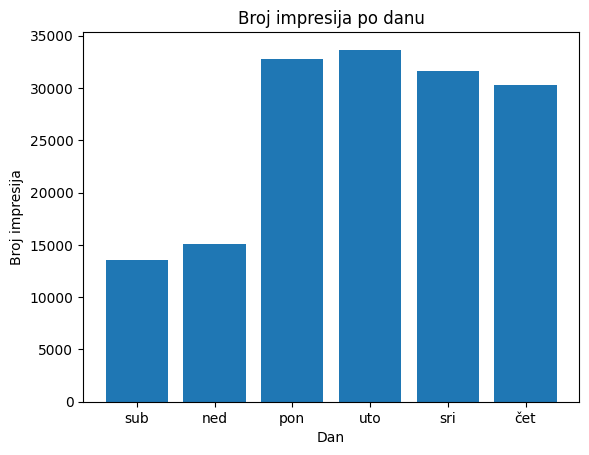

In [20]:
import matplotlib.pyplot as plt
dani = ["sub", "ned", "pon", "uto", "sri", "čet"]
counts = behaviors["Time"].dt.date.value_counts().sort_index()

plt.bar(dani, counts.values)
plt.title("Broj impresija po danu")
plt.xlabel("Dan")
plt.ylabel("Broj impresija")
plt.show()

Vremenski raspon skupa je 6 dana od 2019-11-09 00:00:19 do 2019-11-14 23:59:13.

Broj impresija po danu pokazuje razliku između vikenda i radnih dana.



In [21]:
print("Ukupan broj impresija:", len(behaviors))

klikovi = behaviors["Impressions"].str.count("-1").sum()
prikazi = behaviors["Impressions"].str.count("-0").sum()
print("Ukupno klikova:", klikovi)
print("Ukupno ne-klikova:", prikazi)
print("CTR:", round(klikovi / (klikovi + prikazi), 4))

print("\nBroj kandidata po impresiji:")
print(behaviors["Impressions"].str.split().str.len().describe())

Ukupan broj impresija: 156965
Ukupno klikova: 236344
Ukupno ne-klikova: 5607100
CTR: 0.0404

Broj kandidata po impresiji:
count    156965.000000
mean         37.227688
std          38.594148
min           2.000000
25%          10.000000
50%          24.000000
75%          51.000000
max         299.000000
Name: Impressions, dtype: float64


Skup sadrži 156965 impresija. Ukupan broj klikova je 236344, a ne klikova 5607100 što daje stopu klikova od oko 4% odnosno korisnik klikne na 1 članak od 25 ponuđenih.

Broj članka po impresiji varira od 2 do 299. Medijan je 24 a prosjek je 37 što ukazuje na neravnomjernu veličinu impresija odnosno ekstremi znatno povećavaju prosjek.



In [22]:
print("Broj članaka po kategoriji:")
print(news_clean["Category"].value_counts())

print("\nUkupan broj kategorija:", news_clean["Category"].nunique())

Broj članaka po kategoriji:
Category
news             15774
sports           14510
finance           3107
foodanddrink      2551
lifestyle         2479
travel            2350
video             2068
weather           2048
health            1885
autos             1639
tv                 889
music              769
movies             606
entertainment      587
kids                17
middleeast           2
northamerica         1
Name: count, dtype: int64

Ukupan broj kategorija: 17


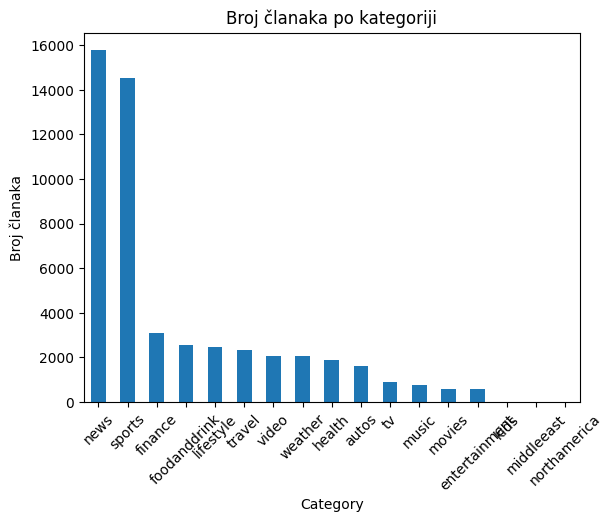

In [23]:
news_clean["Category"].value_counts().plot(kind="bar")
plt.title("Broj članaka po kategoriji")
plt.ylabel("Broj članaka")
plt.xticks(rotation=45)
plt.show()

Ukupno ima 17 glavnih kategorija te je raspodjela neravnomjerna a kategorije news i sports imaju puno veći broj članaka od ostalih kategorija.

In [24]:
print("Duljina naslova (u riječima):")
print(news_clean["Title"].str.split().str.len().describe())

print("\nDuljina sažetka (u riječima):")
print(news_clean["Abstract"].str.split().str.len().describe())

Duljina naslova (u riječima):
count    51282.000000
mean        10.754417
std          3.265311
min          1.000000
25%          9.000000
50%         10.000000
75%         13.000000
max         57.000000
Name: Title, dtype: float64

Duljina sažetka (u riječima):
count    48616.000000
mean        36.173893
std         25.983214
min          1.000000
25%         17.000000
50%         25.000000
75%         64.000000
max        474.000000
Name: Abstract, dtype: float64


Naslovi su kratki i ujednačeni prosjek je 10,75 a medijan na 10 riječi čime se poklapaju a 75% naslova ima najviše 13 riječi.

Sažeci su znatno duži i imaju više varijabilnosti prosjek im je od 36,2 riječi a medijan 25 riječi što znači da raspodjelu vuku dugački sažeci.

In [25]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_rijeci = set(ENGLISH_STOP_WORDS)

def broj_rijeci_bez_stop(tekst):
    if not isinstance(tekst, str):
        return 0

    rijeci = re.findall(r"\w+", tekst.lower())
    rijeci_bez_stop = [rijec for rijec in rijeci if rijec not in stop_rijeci]

    return len(rijeci_bez_stop)


duljina_naslova_bez_stop = news_clean["Title"].apply(broj_rijeci_bez_stop)
duljina_sazetka_bez_stop = news_clean["Abstract"].apply(broj_rijeci_bez_stop)

print("Duljina naslova bez stop riječi:")
print(duljina_naslova_bez_stop.describe())

print("\nDuljina sažetka bez stop riječi:")
print(duljina_sazetka_bez_stop.describe())

Duljina naslova bez stop riječi:
count    51282.000000
mean         7.976580
std          2.408291
min          1.000000
25%          6.000000
50%          8.000000
75%          9.000000
max         31.000000
Name: Title, dtype: float64

Duljina sažetka bez stop riječi:
count    51282.000000
mean        20.614192
std         15.954571
min          0.000000
25%          9.000000
50%         15.000000
75%         36.000000
max        259.000000
Name: Abstract, dtype: float64


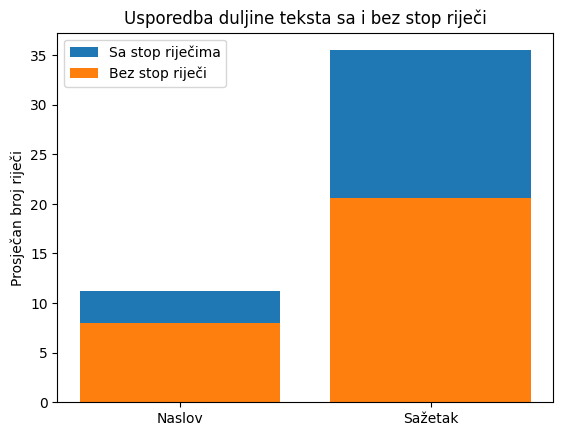

Naslov:
  Stop riječi: 28.74%
  Bez stop riječi: 71.26%
Sažetak:
  Stop riječi: 41.90%
  Bez stop riječi: 58.10%


In [26]:
import matplotlib.pyplot as plt

sa_stop = [
    news_clean["Title"].fillna("").str.lower()
    .str.findall(r"\w+").str.len().mean(),

    news_clean["Abstract"].fillna("").str.lower()
    .str.findall(r"\w+").str.len().mean()
]

bez_stop = [
    duljina_naslova_bez_stop.mean(),
    duljina_sazetka_bez_stop.mean()
]

x = ["Naslov", "Sažetak"]

plt.bar(x, sa_stop, label="Sa stop riječima")
plt.bar(x, bez_stop, label="Bez stop riječi")

plt.ylabel("Prosječan broj riječi")
plt.title("Usporedba duljine teksta sa i bez stop riječi")
plt.legend()
plt.show()

for naziv, ukupno, bez in zip(x, sa_stop, bez_stop):
    udio_stop = (ukupno - bez) / ukupno * 100
    udio_bez = bez / ukupno * 100

    print(f"{naziv}:")
    print(f"  Stop riječi: {udio_stop:.2f}%")
    print(f"  Bez stop riječi: {udio_bez:.2f}%")

Iz rezultata je vidljivo kako stop riječi čine 28,74 % riječi u naslovima, dok je njihov udio u sažecima veći i iznosi 41,90 %. Nakon njihova uklanjanja u naslovima ostaje 71,26 % riječi, a u sažecima 58,10 %. Time se kod pripreme BoW i TF-IDF reprezentacija uklanja veći udio riječi iz sažetaka nego iz naslova.

In [27]:
prosjek_sa_stop = sum(sa_stop)
prosjek_bez_stop = sum(bez_stop)

udio_stop = (prosjek_sa_stop - prosjek_bez_stop) / prosjek_sa_stop * 100
udio_bez_stop = prosjek_bez_stop / prosjek_sa_stop * 100

print("\nProsječno po članku (naslov + sažetak):")
print(f"Sa stop riječima: {prosjek_sa_stop:.2f} riječi")
print(f"Bez stop riječi: {prosjek_bez_stop:.2f} riječi")
print(f"Udio stop riječi: {udio_stop:.2f}%")
print(f"Udio bez stop riječi: {udio_bez_stop:.2f}%")


Prosječno po članku (naslov + sažetak):
Sa stop riječima: 46.67 riječi
Bez stop riječi: 28.59 riječi
Udio stop riječi: 38.74%
Udio bez stop riječi: 61.26%


Nakon uklanjanja stop riječi prosječan broj riječi po članku smanjuje se s 46,67 na 28,59, odnosno za 38,74 %.

In [28]:
import re

tekst = (
    news_clean["Title"].fillna("") + " " +
    news_clean["Abstract"].fillna("")
)

# Ukupan broj tokena sa stop riječima
ukupno_tokena = tekst.apply(
    lambda x: len(re.findall(r"\w+", x.lower()))
).sum()

print("Ukupan broj tokena u korpusu:", ukupno_tokena)


# Broj tokena nakon uklanjanja stop riječi
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_rijeci = set(ENGLISH_STOP_WORDS)

ukupno_tokena_bez_stop = tekst.apply(
    lambda x: len([
        token for token in re.findall(r"\w+", x.lower())
        if token not in stop_rijeci
    ])
).sum()

broj_stop_rijeci = ukupno_tokena - ukupno_tokena_bez_stop

print("Broj stop riječi:", broj_stop_rijeci)
print("Broj tokena bez stop riječi:", ukupno_tokena_bez_stop)
print(
    "Udio stop riječi:",
    round(broj_stop_rijeci / ukupno_tokena * 100, 2),
    "%"
)


# Veličina vokabulara
from sklearn.feature_extraction.text import CountVectorizer

for min_df in [2, 5]:
    vec = CountVectorizer(
        min_df=min_df,
        stop_words="english"
    )
    vec.fit(tekst)

    print(
        f"Veličina vokabulara (min_df={min_df}, bez stop riječi):",
        len(vec.vocabulary_)
    )

Ukupan broj tokena u korpusu: 2393465
Broj stop riječi: 927273
Broj tokena bez stop riječi: 1466192
Udio stop riječi: 38.74 %
Veličina vokabulara (min_df=2, bez stop riječi): 32700
Veličina vokabulara (min_df=5, bez stop riječi): 18646


Korpus se sastoji od naslova i sažetaka svih članaka. Ukupan broj tokena u korpusu iznosi 2393465 a broj tokena bez zaustavnih riječi iznosi 1466192. Uz uvjet da riječ mora biti u barem 2 članka ima 32700 riječi a 18646 riječi ispunjava uvjet da riječ mora biti u barem 5 članaka.

In [29]:
cutoff = pd.Timestamp("2019-11-14 00:00:00")

prije = behaviors[behaviors["Time"] < cutoff]
poslije = behaviors[behaviors["Time"] >= cutoff]

print("Impresije prije vremenske granice:", len(prije))
print("Impresije nakon vremenske granice:", len(poslije))

korisnici_prije = set(prije["UserID"])
korisnici_poslije = set(poslije["UserID"])
korisnici_oba = korisnici_prije & korisnici_poslije

print("\nKorisnika prije:", len(korisnici_prije))
print("Korisnika poslije:", len(korisnici_poslije))
print("Korisnika u oba:", len(korisnici_oba))



Impresije prije vremenske granice: 126695
Impresije nakon vremenske granice: 30270

Korisnika prije: 46012
Korisnika poslije: 20179
Korisnika u oba: 16191


Prije vremenske granice nalazi se 126.695 impresija, a nakon nje 30270. U oba razdoblja pojavljuje se 16.191 korisnik.

/tmp/ipykernel_624/1761227713.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  per_hour = behaviors.set_index("Time").resample("1H").size()


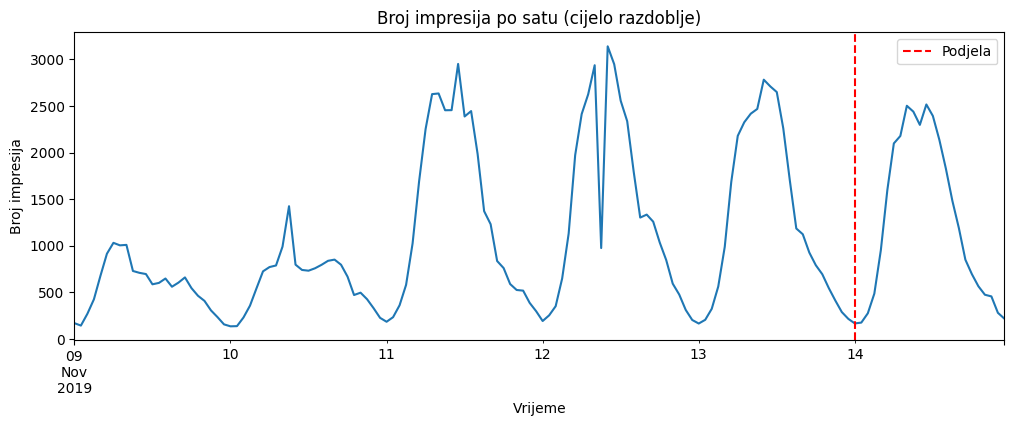

In [30]:
per_hour = behaviors.set_index("Time").resample("1H").size()
plt.figure(figsize=(12,4))
per_hour.plot()
plt.axvline(pd.Timestamp("2019-11-14 00:00:00"), color="red", linestyle="--", label="Podjela")
plt.title("Broj impresija po satu (cijelo razdoblje)")
plt.xlabel("Vrijeme"); plt.ylabel("Broj impresija"); plt.legend()
plt.show()

Budući da je u projektu korišten trening dio skupa MIND-small preuzet s Kagglea, za potrebe projekta bilo je potrebno dodatno izdvojiti evaluacijski dio iz tih podataka. Kao granicu koja razdvaja trening dio od evaluacijskog dijela je postavljen datum 14.11.2019. u 00:00. Također je provedena provjera kojom se utvrđuje koliko korinsika ima impresija i u trening i u evaluacijskom dijelu.

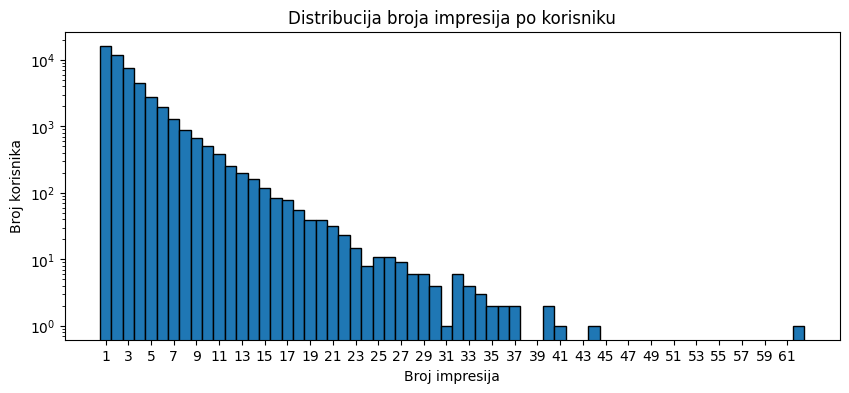

In [31]:
max_val = int(impresije_per_user.max())

plt.figure(figsize=(10,4))
plt.hist(impresije_per_user, bins=range(1, max_val+2), edgecolor="black", align="left")
plt.title("Distribucija broja impresija po korisniku")
plt.xlabel("Broj impresija"); plt.ylabel("Broj korisnika")
plt.yscale("log")
plt.xticks(range(1, max_val+1, 2))
plt.show()

In [32]:
#Priprema vektorskih reprezentacija

In [33]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

vektorizator_bow = CountVectorizer(stop_words="english", lowercase=True, min_df=5)
X_bow = vektorizator_bow.fit_transform(tekst)

vektorizator_tfidf = TfidfVectorizer(stop_words="english", lowercase=True, min_df=5)
X_tfidf = vektorizator_tfidf.fit_transform(tekst)

print("Oblik BoW matrice:", X_bow.shape)
print("Oblik TF-IDF matrice:", X_tfidf.shape)
print("Veličina rječnika BoW:", len(vektorizator_bow.vocabulary_))
print("Veličina rječnika TF-IDF:", len(vektorizator_tfidf.vocabulary_))

print("BoW, broj članaka s nultim vektorom:",
      (X_bow.getnnz(axis=1) == 0).sum())
print("TF-IDF, broj članaka s nultim vektorom:",
      (X_tfidf.getnnz(axis=1) == 0).sum())

Oblik BoW matrice: (51282, 18646)
Oblik TF-IDF matrice: (51282, 18646)
Veličina rječnika BoW: 18646
Veličina rječnika TF-IDF: 18646
BoW, broj članaka s nultim vektorom: 0
TF-IDF, broj članaka s nultim vektorom: 0


U ovom dijelu provedena je pretvorba riječi u vektore. Kreiraju se rječnici i matrice članaka u kojima se nalaze samo riječi koje se pojavljuju u barem 5 članaka. Bow broji koliko se riječi pojavljuju u članku, a TF-IDF dodatno vrednuje riječi prema njihovoj rijetkosti u korpusu.

In [34]:
from sklearn.decomposition import TruncatedSVD

dimenzije = [100, 200, 300]

bow_svd = {}
for d in dimenzije:
    svd = TruncatedSVD(n_components=d, random_state=42)
    bow_svd[d] = svd.fit_transform(X_bow)

lsa_svd = {}
for d in dimenzije:
    svd = TruncatedSVD(n_components=d, random_state=42)
    lsa_svd[d] = svd.fit_transform(X_tfidf)

for d in dimenzije:
    print(f"BoW-{d}:", bow_svd[d].shape)
for d in dimenzije:
    print(f"LSA-{d}:", lsa_svd[d].shape)

BoW-100: (51282, 100)
BoW-200: (51282, 200)
BoW-300: (51282, 300)
LSA-100: (51282, 100)
LSA-200: (51282, 200)
LSA-300: (51282, 300)


Kako su BoW i TF-IDF rijetke matrice bilo ih je potrebno svesti na guste matrice manje dimenzionalnosti pa je za to korišten TruncatedSVD koji zadržava komponente povezane s najvećim singularnim vrijednostima, pri čemu nove komponente predstavljaju kombinacije izvornih značajki. Na taj način su BoW i TF-IDF svedeni na iste dimenzije kao Word2Vec i FastText.

In [35]:
import gensim.downloader as api

fasttext_model = api.load("fasttext-wiki-news-subwords-300")
word2vec_model = api.load("word2vec-google-news-300")

print(fasttext_model.vector_size)
print(word2vec_model.vector_size)

[==================================================] 100.0% 958.5/958.4MB downloaded
[==================================================] 100.0% 1662.8/1662.8MB downloaded
300
300


U ovome dijelu su preuzeta 2 pretrenirana modela FastText i Word2Vec te oba imaju fiksnu dimenziju 300.

In [36]:
import re
import numpy as np

def prosjek_vektora(text, model):
    rijeci = re.findall(r"\w+", text.lower())
    vektori = [model[r] for r in rijeci if r in model]
    if len(vektori) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vektori, axis=0)

fasttext_vektori = np.array([prosjek_vektora(t, fasttext_model) for t in tekst])
word2vec_vektori = np.array([prosjek_vektora(t, word2vec_model) for t in tekst])

print("Oblik FastText matrice:", fasttext_vektori.shape)
print("Oblik Word2Vec matrice:", word2vec_vektori.shape)

print("FastText, broj članaka s nultim vektorom:",
      np.all(fasttext_vektori == 0, axis=1).sum())
print("Word2Vec, broj članaka s nultim vektorom:",
      np.all(word2vec_vektori == 0, axis=1).sum())

Oblik FastText matrice: (51282, 300)
Oblik Word2Vec matrice: (51282, 300)
FastText, broj članaka s nultim vektorom: 0
Word2Vec, broj članaka s nultim vektorom: 2


U ovome dijelu provjeren je broj članaka s nultim vektorom. Kod FastTexta nema takvih članaka, dok kod Word2Veca dva članka imaju nulti vektor.

In [37]:
from sklearn.decomposition import TruncatedSVD

fasttext_svd = {300: fasttext_vektori}
word2vec_svd = {300: word2vec_vektori}

for d in [100, 200]:
    svd = TruncatedSVD(n_components=d, random_state=42)
    fasttext_svd[d] = svd.fit_transform(fasttext_vektori)

for d in [100, 200]:
    svd = TruncatedSVD(n_components=d, random_state=42)
    word2vec_svd[d] = svd.fit_transform(word2vec_vektori)

for d in [100, 200, 300]:
    print(f"FastText-{d}:", fasttext_svd[d].shape)
for d in [100, 200, 300]:
    print(f"Word2Vec-{d}:", word2vec_svd[d].shape)

FastText-100: (51282, 100)
FastText-200: (51282, 200)
FastText-300: (51282, 300)
Word2Vec-100: (51282, 100)
Word2Vec-200: (51282, 200)
Word2Vec-300: (51282, 300)


In [38]:
from sklearn.preprocessing import normalize

svi_vektori = {
    "BoW": bow_svd,
    "LSA": lsa_svd,
    "FastText": fasttext_svd,
    "Word2Vec": word2vec_svd,
}

normalizirano = {}
for tip, rjecnik in svi_vektori.items():
    normalizirano[tip] = {}
    for d, matrica in rjecnik.items():
        normalizirano[tip][d] = normalize(matrica, norm="l2", axis=1)

for tip, rjecnik in normalizirano.items():
    for d in sorted(rjecnik.keys()):
        norme = np.linalg.norm(rjecnik[d], axis=1)
        print(f"{tip}-{d}: oblik={rjecnik[d].shape}, prosječna norma={norme.mean():.4f}, min norma={norme.min():.4f}")

BoW-100: oblik=(51282, 100), prosječna norma=1.0000, min norma=1.0000
BoW-200: oblik=(51282, 200), prosječna norma=1.0000, min norma=1.0000
BoW-300: oblik=(51282, 300), prosječna norma=1.0000, min norma=1.0000
LSA-100: oblik=(51282, 100), prosječna norma=1.0000, min norma=1.0000
LSA-200: oblik=(51282, 200), prosječna norma=1.0000, min norma=1.0000
LSA-300: oblik=(51282, 300), prosječna norma=1.0000, min norma=1.0000
FastText-100: oblik=(51282, 100), prosječna norma=1.0000, min norma=1.0000
FastText-200: oblik=(51282, 200), prosječna norma=1.0000, min norma=1.0000
FastText-300: oblik=(51282, 300), prosječna norma=1.0000, min norma=1.0000
Word2Vec-100: oblik=(51282, 100), prosječna norma=1.0000, min norma=0.0000
Word2Vec-200: oblik=(51282, 200), prosječna norma=1.0000, min norma=0.0000
Word2Vec-300: oblik=(51282, 300), prosječna norma=1.0000, min norma=0.0000


Provedena je normalizacija vektora nad BoW, LSA, FastText i Word2Vec iz razloga što različiti tipovi reprezentacija imaju različite vrijednosti skale. U neuronskoj mreži razičite skale utječu na veličinu gradijenata pa mogu utjecati i na odabir learning_rate. S L2 normalizacijom svaki nenulti vektor članka dobija jediničnu duljinu, dok nulti vektori ostaju nulti, te su s time ujednačene duljine nenultih vektora svih reprezentacija.

In [39]:
aktivne_kategorije = news_clean["Category"].value_counts()
aktivne_kategorije = aktivne_kategorije[~aktivne_kategorije.index.isin(["kids", "middleeast", "northamerica"])].index.tolist()

maska_aktivnih = news_clean["Category"].isin(aktivne_kategorije).values
indeksi = np.arange(len(news_clean))[maska_aktivnih]
y = news_clean.loc[maska_aktivnih, "Category"].values

from sklearn.model_selection import train_test_split

idx_train, idx_test, y_train, y_test = train_test_split(indeksi, y, test_size=0.2, stratify=y, random_state=42)

baseline = pd.Series(y).value_counts(normalize=True).max()
najrjede = pd.Series(y).value_counts().sort_values().head(5).index.tolist()

print("Trening:", len(idx_train), "Test:", len(idx_test))
print("Udio najveće kategorije:", round(baseline, 4))
print("Pet najrjeđih aktivnih kategorija:", najrjede)

Trening: 41009 Test: 10253
Udio najveće kategorije: 0.3077
Pet najrjeđih aktivnih kategorija: ['entertainment', 'movies', 'music', 'tv', 'autos']


U ovome dijelu izostavljene su tri prethodno analizirane kategorije, kids, middleeast i northamerica, zbog malog broja članaka. Članci iz tih kategorija nisu uključeni u provjeru logističkom regresijom. Nakon toga provedena je podjela članaka na trening i testni skup u omjeru 80 % za trening i 20 % za test. Ova podjela odvojena je od podjele korisničkih impresija za treniranje i evaluaciju DQN agenta. Također je izračunat udio najveće kategorije, koji iznosi oko 31 %, pa klasifikator treba ostvariti veću točnost kako bi nadmašio pretpostavku da svaki članak pripada najvećoj kategoriji.

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

svi_svd = normalizirano
rezultati = []

for tip, rjecnik in svi_svd.items():
    for d, matrica in rjecnik.items():
        X_train = matrica[idx_train]
        X_test = matrica[idx_test]
        clf = LogisticRegression(max_iter=1000, random_state=42)
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        red = {
            "tip": tip,
            "D": d,
            "accuracy": accuracy_score(y_test, y_pred),
            "macro_f1": f1_score(y_test, y_pred, average="macro"),
        }
        per_class = f1_score(y_test, y_pred, labels=najrjede, average=None)
        for kat, f1 in zip(najrjede, per_class):
            red[f"f1_{kat}"] = f1
        rezultati.append(red)


rezultati_df = pd.DataFrame(rezultati)
rezultati_df

,tip,D,accuracy,macro_f1,f1_entertainment,f1_movies,f1_music,f1_tv,f1_autos
0,BoW,100,0.629279,0.364354,0.093960,0.237762,0.252427,0.121495,0.396226
1,BoW,200,0.665074,0.438102,0.203822,0.243590,0.384615,0.237154,0.464088
2,BoW,300,0.678241,0.472411,0.236842,0.317647,0.460251,0.287879,0.490161
3,LSA,100,0.680679,0.474477,0.285714,0.312139,0.414634,0.291339,0.545763
4,LSA,200,0.700771,0.516977,0.355828,0.311111,0.513208,0.345515,0.577250
5,LSA,300,0.715791,0.551369,0.392857,0.459330,0.556863,0.364286,0.615126
6,FastText,300,0.705940,0.491655,0.140625,0.266667,0.431925,0.241667,0.593449
7,FastText,100,0.697845,0.468485,0.140625,0.236111,0.305419,0.186667,0.573643
8,FastText,200,0.705745,0.492657,0.140625,0.281879,0.429907,0.246914,0.600000
9,Word2Vec,300,0.739588,0.602957,0.402299,0.558824,0.671429,0.430108,0.675958


U ovome dijelu je provedeni testni eksperiment u kojem se ispituje koliko pojedina vektorska reprezentacija utječe na signal o pripadnosti članka određenoj kategoriji. Iz vektora članaka trenirana je logistička regresija koja predviđa glavnu kategoriju. Iz rezultata se može vidjeti kako veće dimenzije uglavnom pomažu boljem signalu koji ukazuje na određenu kategoriju, te kako je Word2Vec najbolji prema ukupnoj točnosti i macro F1, dok FastText prema macro F1 ostvaruje bolje rezultate od BoW-a, a slabije od LSA-e u svim trima dimenzionalnostima. Moguće objašnjenje razlika je što su ova 2 modela trenirana na različitim korpusima. Word2Vec je treniran na Google News korpusu dok je korišteni FastText treniran na Wikipediji, UMBC web tekstovima i novinskim tekstovima. Sličnost MIND korpusa i Google Newsa mogla je pridonijeti rezultatima Word2Veca, ali ovim eksperimentom nije potvrđeno da je to razlog njegove prednosti.

Kako je iz prethodnih analiza vidljivo kako određene kategorije dominiraju, odnosno imaju puno veći broj članaka. Zbog toga na accuracy više utječu rezultati zastupljenijih kategorija, dok kod macro F1 svaka kategorija daje jednak doprinos prosjeku pa zbog toga se može reći kako sami odnosi između accuracy i macro F1 imaju smisla.
Također je vidljivo da veće dimenzije kod dijela manje zastupljenih kategorija povećavaju F1 vrijednosti, ali poboljšanje nije jednako kod svih kategorija i reprezentacija. FastText se kod pojedinih manjih kategorija pokazuje slabijim od ostalih promatranih vektorskih reprezentacija, ali nije najlošiji u svim slučajevima.

In [41]:
# Priprema kandidata i populacije

In [42]:
import numpy as np
import pandas as pd
from IPython.display import display

H = 5
GAMMA = 0.95
MIN_KANDIDATA = 7
SEED_UZORKOVANJA = 2026
BROJ_TRENING_KORISNIKA = 10000
BROJ_VALIDACIJSKIH_KORISNIKA = 3000

news_id_redoslijed = news_clean["NewsID"].astype(str).to_numpy()
news_idx = {news_id: i for i, news_id in enumerate(news_id_redoslijed)}
TIP, D = "Word2Vec", 200
vektori = np.asarray(normalizirano[TIP][D], dtype=np.float32)
norme_vektora = np.linalg.norm(vektori, axis=1)

Epizoda sadrži točno pet odabira. Faktor diskontiranja 0,95 daje
veću težinu ranijim klikovima. Prihvaćaju se impresije koje nakon
filtriranja imaju najmanje sedam različitih kandidata. Oznake članaka
povezuju se s redovima već pripremljenih vektorskih matrica.

In [43]:
kategorija_po_id = dict(zip(
    news_clean["NewsID"].astype(str),
    news_clean["Category"],
))

valjani_clanci = (
    np.linalg.norm(normalizirano["LSA"][300], axis=1) > 0
)

dopusteni_clanci = {
    news_id
    for news_id, i in news_idx.items()
    if valjani_clanci[i]
    and kategorija_po_id.get(news_id) in aktivne_kategorije
}

Za sve reprezentacije koristi se isti katalog dopuštenih članaka.
U njemu su članci iz 14 aktivnih kategorija s nenultim LSA vektorom
dimenzije 300. Time se ponuda kandidata ne mijenja pri usporedbi vektora.

In [44]:
def profil_iz_povijesti(history, alpha=0.05):
    profil = np.zeros(D, dtype=np.float32)

    history_ids = (
        [] if pd.isna(history) else str(history).split()
    )

    for news_id in history_ids:
        i = news_idx.get(news_id)

        if i is not None and norme_vektora[i] > 0:
            profil = (
                (1 - alpha) * profil
                + alpha * vektori[i]
            )

    norma = np.linalg.norm(profil)

    return profil / norma if norma > 0 else profil

Profil korisnika računa se iz članaka navedenih u njegovu polju History, pri čemu se koriste samo članci s dostupnim nenultim vektorom. Eksponencijalno ponderiranje s vrijednošću 0,05 daje veću težinu kasnijim člancima u tom zapisu. Dobiveni nenulti profil se L2 normalizira. Tijekom jedne epizode profil ostaje isti.

In [45]:
def pripremi_kandidate(impressions, rng=None):
    if pd.isna(impressions):
        return None
    oznake = {}
    for zapis in str(impressions).split():
        news_id, oznaka = zapis.rsplit("-", 1)
        if oznaka not in {"0", "1"}:
            raise ValueError("Neispravna oznaka klika.")
        if news_id in oznake and oznake[news_id] != int(oznaka):
            raise ValueError("Članak ima proturječne oznake u istoj impresiji.")
        oznake[news_id] = int(oznaka)

    parovi = [(news_idx[n], y) for n, y in oznake.items()
              if n in dopusteni_clanci]
    if not parovi:
        return None
    a, y = map(np.asarray, zip(*parovi))
    if len(a) < MIN_KANDIDATA or y.sum() < 1 or (y == 0).sum() < 4:
        return None
    if rng is not None:
        redoslijed = rng.permutation(len(a))
        a, y = a[redoslijed], y[redoslijed]
    return a.astype(np.int64), y.astype(np.float32)

Iz svake impresije izdvajaju se svi različiti dopušteni članci i
njihove zabilježene oznake. Zadržavaju se impresije s najmanje sedam
kandidata, barem jednim klikom i najmanje četiri neklika. Ne uzorkuje se nova lista
od pet članaka. Rezultati se zato odnose na ovaj izdvojeni dio podataka.

In [46]:
import random

svi_korisnici = behaviors["UserID"].astype(str).unique().tolist()

random.seed(42)

random.shuffle(svi_korisnici)

broj_trening = int(0.8 * len(svi_korisnici))

trening_korisnici = set(
    svi_korisnici[:broj_trening]
)

novi_korisnici = set(
    svi_korisnici[broj_trening:]
)



Korisnici se jednom dijele na 80 % za pripremu treninga i validacije
te 20 % izdvojenih korisnika. Seed 42 osigurava istu podjelu pri novom
pokretanju. Korisnici iz izdvojene skupine ne sudjeluju u učenju težina.

In [47]:
def uredi_impresije(tablica):
    t = tablica.copy()
    t["UserID"] = t["UserID"].astype(str)
    t["ImpressionID"] = t["ImpressionID"].astype(str)
    t["Time"] = pd.to_datetime(t["Time"])

    return (
        t.sort_values(["UserID", "Time", "ImpressionID"])
        .reset_index(drop=True)
    )


ranije = uredi_impresije(prije)
kasnije = uredi_impresije(poslije)

ranije = ranije[
    ranije["UserID"].isin(trening_korisnici)
]

validacijski_indeksi = (
    ranije
    .groupby("UserID", sort=False)
    .tail(1)
    .index
)

tablice = {
    "trening": ranije.drop(index=validacijski_indeksi).copy(),
    "validacija": ranije.loc[validacijski_indeksi].copy(),
}

Koristi se prethodno postavljena vremenska granica. Posljednja impresija prije te granice odvaja se za validaciju svakog korisnika iz skupine za pripremu treninga i validacije, a ranije impresije ostaju za trening. Korisnik sa samo jednom
ranijom impresijom može biti samo u validaciji.

In [48]:
def izdvoji_prihvatljive(tablica):
    maska = tablica["Impressions"].map(
        lambda s: pripremi_kandidate(s) is not None
    )

    t = tablica.loc[maska].copy().reset_index(drop=True)

    t["cold_start"] = (
        t["History"].fillna("").astype(str).str.strip().eq("")
    )

    return t


podaci = {
    naziv: izdvoji_prihvatljive(t)
    for naziv, t in tablice.items()
}

odabrani_trening_korisnici = (
    podaci["trening"]["UserID"].drop_duplicates()
    .sample(n=min(BROJ_TRENING_KORISNIKA, podaci["trening"]["UserID"].nunique()),
            random_state=SEED_UZORKOVANJA)
)
podaci["trening"] = podaci["trening"].loc[
    podaci["trening"]["UserID"].isin(odabrani_trening_korisnici)
].reset_index(drop=True)

val = podaci["validacija"]
validacijski_uzorak = np.sort(np.random.default_rng(SEED_UZORKOVANJA).choice(
    len(val), size=min(BROJ_VALIDACIJSKIH_KORISNIKA, len(val)), replace=False))
podaci["validacija"] = val.iloc[validacijski_uzorak].reset_index(drop=True)

poznati_korisnici = set(podaci["trening"]["UserID"])

for naziv, korisnici in [
    ("eval_poznati", poznati_korisnici),
    ("eval_novi", novi_korisnici),
]:
    tablice[naziv] = kasnije[
        kasnije["UserID"].isin(korisnici)
    ].copy()
    podaci[naziv] = izdvoji_prihvatljive(tablice[naziv])

pd.DataFrame([
    {
        "skup": naziv,
        "korisnici": t["UserID"].nunique(),
        "impresije": len(t),
    }
    for naziv, t in podaci.items()
])

,skup,korisnici,impresije
0,trening,10000,26029
1,validacija,3000,3000
2,eval_poznati,4052,6543
3,eval_novi,3735,5518


Jednaki uvjeti prihvatljivosti primjenjuju se na sve skupove. U trening ulaze korisnici kojima je nakon izdvajanja validacije ostala barem jedna prihvatljiva trening impresija. Za trening se nasumično odabire najviše 10.000 prihvatljivih korisnika. Odabir se provodi jednom i isti je za sve reprezentacije i seedove. Validacija koristi fiksni uzorak od najviše 3.000 korisnika, koji ne moraju svi biti među konačno odabranim trening korisnicima. Poznati evaluacijski korisnici sudjelovali su u treningu, dok su novi izdvojeni pri početnoj podjeli. Oznaka cold_start znači da je History te impresije prazan, pa novi korisnik u evaluaciji ne mora biti bez povijesti.

In [49]:
prve_povijesti = (
    podaci["trening"]
    .drop_duplicates("UserID")["History"]
)

pocetni_profili = [
    profil_iz_povijesti(h)
    for h in prve_povijesti
]

pocetni_profili = [
    p for p in pocetni_profili
    if np.linalg.norm(p) > 0
]

if not pocetni_profili:
    raise ValueError("Nema valjanih trening profila.")

prosjecni_profil = np.mean(
    pocetni_profili, axis=0
).astype(np.float32)

norma_prosjeka = np.linalg.norm(prosjecni_profil)

if norma_prosjeka == 0:
    raise ValueError("Prosječni profil je nulti vektor.")

prosjecni_profil /= norma_prosjeka

Za impresije bez valjanog osobnog profila računa se prosječni profil. Uzima se povijest iz prve zadržane trening impresije svakog korisnika, a u prosjek ulaze samo nenulti profili. Svaki uključeni korisnik daje jednak doprinos prosjeku, koji se zatim L2 normalizira. Podaci iz validacijskog i završnih evaluacijskih skupova ne koriste se za taj izračun.

In [50]:
def pocetni_profil(history):
    profil = profil_iz_povijesti(history)

    return (
        profil
        if np.linalg.norm(profil) > 0
        else prosjecni_profil.copy()
    )


def matrica_profila(tablica):
    return np.stack([
        pocetni_profil(h)
        for h in tablica["History"]
    ])


profili_trening = matrica_profila(podaci["trening"])

Svaka impresija dobiva profil iz vlastite prethodne povijesti.
Ako nije moguće izračunati valjan profil, koristi se prosječni trening
profil. Profili se pripremaju unaprijed radi bržeg izvođenja treninga.

In [51]:
kontrola = {
    naziv: (t.groupby("UserID", sort=False).head(2).reset_index(drop=True)
            if naziv == "trening" else t)
    for naziv, t in podaci.items()
}


def generiraj_epizode(tablica, seed):
    rng = np.random.default_rng(seed)
    return [pripremi_kandidate(s, rng) for s in tablica["Impressions"]]


trening_epizode = generiraj_epizode(podaci["trening"], SEED_UZORKOVANJA)
fiksne_epizode = {
    naziv: generiraj_epizode(t, 100 + i)
    for i, (naziv, t) in enumerate(kontrola.items())
}
profili_kontrole = {naziv: matrica_profila(t) for naziv, t in kontrola.items()}

display(pd.DataFrame([
    {"skup": naziv, "impresije": len(ep),
     "kandidati_medijan": np.median([len(a) for a, y in ep]),
     "kandidati_max": max(len(a) for a, y in ep)}
    for naziv, ep in fiksne_epizode.items()
]))

,skup,impresije,kandidati_medijan,kandidati_max
0,trening,15692,31.0,294
1,validacija,3000,31.0,299
2,eval_poznati,6543,32.0,292
3,eval_novi,5518,30.0,294


Kandidati i njihov početni redoslijed pripremaju se jednom i ostaju
isti za svih 12 kombinacija. Jedan puni trening krug prolazi sve
prihvatljive trening impresije. Samo izvještaj na trening podacima
koristi najviše dvije impresije po korisniku, validacija koristi odabrani uzorak, a završna
evaluacija sve prihvatljive impresije svojih skupova.

In [52]:
def clanci_iz_epizoda(epizode):
    return {
        int(indeks)
        for kandidati, oznake in epizode
        for indeks in kandidati
    }


clanci_trening = clanci_iz_epizoda(trening_epizode)

print(
    "Broj jedinstvenih članaka među trening kandidatima:",
    len(clanci_trening),
)

for naziv_skupa in ["validacija", "eval_poznati", "eval_novi"]:
    clanci_skupa = clanci_iz_epizoda(fiksne_epizode[naziv_skupa])
    novi_clanci = clanci_skupa - clanci_trening

    udio_novih = (
        100 * len(novi_clanci) / len(clanci_skupa)
        if clanci_skupa else 0.0
    )

    print(f"\nSkup: {naziv_skupa}")
    print(" Broj jedinstvenih članaka među kandidatima:", len(clanci_skupa))
    print(" Članci koji nisu bili među trening kandidatima:", len(novi_clanci))
    print(f" Udio takvih članaka: {udio_novih:.2f}%")

Broj jedinstvenih članaka među trening kandidatima: 12017

Skup: validacija
 Broj jedinstvenih članaka među kandidatima: 5568
 Članci koji nisu bili među trening kandidatima: 564
 Udio takvih članaka: 10.13%

Skup: eval_poznati
 Broj jedinstvenih članaka među kandidatima: 4290
 Članci koji nisu bili među trening kandidatima: 2702
 Udio takvih članaka: 62.98%

Skup: eval_novi
 Broj jedinstvenih članaka među kandidatima: 4227
 Članci koji nisu bili među trening kandidatima: 2637
 Udio takvih članaka: 62.38%


# Okruženje i DQN mreža

In [ ]:
def korak_okruzenja(oznake, dostupni, odabrani, akcije):
    redovi = np.arange(len(akcije))
    t = (odabrani >= 0).sum(axis=1)
    if (t >= H).any() or not dostupni[redovi, akcije].all():
        raise ValueError("Epizoda je završena ili članak nije dostupan.")
    nagrade = oznake[redovi, akcije].astype(np.float32)
    novi_odabiri = odabrani.copy()
    novi_odabiri[redovi, t] = akcije
    novi_dostupni = dostupni.copy()
    novi_dostupni[redovi, akcije] = False
    gotovo = (t + 1 >= H) | ~novi_dostupni.any(axis=1)
    return novi_odabiri, novi_dostupni, nagrade, gotovo

Klik donosi nagradu 1, a neklik 0. Nakon odabira članak se uklanja iz
ponude. Klik ne završava epizodu, agent nastavlja do pet odabira ili
iscrpljivanja kandidata. Položaji odabranih članaka služe samo za
uklanjanje iz ponude i rekonstrukciju prijelaza. Ne šalju se mreži kao
memorija reakcija.

In [ ]:
import torch
from torch import nn
import torch.nn.functional as F


class CandidateDQN(nn.Module):
    def __init__(self, dimenzija):
        super().__init__()
        self.dimenzija = dimenzija
        self.ulaz = nn.Linear(2 * dimenzija + 1, 256)
        self.izlaz = nn.Sequential(
            nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 1))

    def forward(self, profil, clanci, preostalo):
        d, w = self.dimenzija, self.ulaz.weight
        stanje = torch.cat((profil, preostalo[:, None] / H), dim=1)
        s = F.linear(stanje, torch.cat((w[:, :d], w[:, 2*d:]), dim=1),
                     self.ulaz.bias)
        a = F.linear(clanci, w[:, d:2*d])
        return self.izlaz(s[:, None, :] + a).squeeze(-1)

Mreža za svaki članak koristi korisnički profil, vektor članka i broj preostalih odabira podijeljen s H. Tako kod vektora od 200 dimenzija ukupno prima 401 vrijednost. Mreža ima dva skrivena sloja s 256 i 128 neurona te nakon svakog koristi ReLU. Na izlazu daje jednu Q-vrijednost za pojedini članak. Kako su profil i broj preostalih odabira isti za sve kandidate jedne impresije, njihov dio izračuna radi se jednom pri svakom pozivu mreže. Povijest prethodnih klikova sadržana je u profilu, ali se profil tijekom epizode ne nadopunjuje novim odabirima.

In [ ]:
parametri_mreze = []

for dimenzija in [100, 200, 300]:
    mreza_za_brojanje = CandidateDQN(dimenzija)
    parametri_mreze.append({
        "D": dimenzija,
        "ulazne_vrijednosti": mreza_za_brojanje.ulaz.in_features,
        "parametri_prvog_sloja": sum(
            p.numel() for p in mreza_za_brojanje.ulaz.parameters()
        ),
        "parametri_mreze": sum(
            p.numel() for p in mreza_za_brojanje.parameters()
        ),
    })

parametri_mreze = pd.DataFrame(parametri_mreze)
display(parametri_mreze)
del mreza_za_brojanje


,D,ulazne_vrijednosti,parametri_prvog_sloja,parametri_mreze
0,100,201,51712,84737
1,200,401,102912,135937
2,300,601,154112,187137


U ovome dijelu izračunat je broj parametara mreže za svaku dimenzionalnost. Kod 100 dimenzija mreža prima 201 vrijednost i ima 84 737 parametara, kod 200 dimenzija prima 401 vrijednost i ima 135 937 parametara, a kod 300 dimenzija prima 601 vrijednost i ima 187 137 parametara. Povećanjem dimenzionalnosti korisničkog profila i članka povećava se broj parametara prvog sloja, dok broj neurona u skrivenim slojevima ostaje isti.

In [ ]:
def pripremi_batch(epizode, profili, indeksi, odabrani=None):
    b = len(indeksi)
    n = max(len(epizode[i][0]) for i in indeksi)
    a = np.zeros((b, n), dtype=np.int64)
    y = np.zeros((b, n), dtype=np.float32)
    dostupni = np.zeros((b, n), dtype=bool)
    for red, i in enumerate(indeksi):
        aa, yy = epizode[i]
        a[red, :len(aa)], y[red, :len(aa)] = aa, yy
        dostupni[red, :len(aa)] = True
    if odabrani is None:
        odabrani = np.full((b, H), -1, dtype=np.int64)
    redovi, mjesta = np.where(odabrani >= 0)
    dostupni[redovi, odabrani[redovi, mjesta]] = False
    preostalo = np.minimum(H - (odabrani >= 0).sum(1), dostupni.sum(1))
    return {
        "profili": torch.as_tensor(profili[np.asarray(indeksi)], device=device),
        "a": torch.as_tensor(a, device=device), "y": y,
        "dostupni": dostupni, "odabrani": odabrani.copy(),
        "preostalo": torch.as_tensor(preostalo, dtype=torch.float32, device=device),
    }

Kako impresije nemaju jednak broj kandidata, za zajedničku obradu priprema se matrica prema najvećem broju kandidata u batchu. Kod impresija s manje kandidata ostaju pomoćna mjesta koja maska označava kao nedostupna. Tako se ne dodaju novi kandidati, a maska isključuje i već odabrane članke. Oznake klikova koriste se za nagradu, ali ih mreža ne dobiva kao ulaz pri procjeni članka.

In [ ]:
def q_vrijednosti(mreza, paket):
    q = mreza(paket["profili"], vektori_t[paket["a"]], paket["preostalo"])
    dostupni = torch.as_tensor(paket["dostupni"], device=device)
    return q.masked_fill(~dostupni, -torch.inf)

Mreža računa Q-vrijednost za svakog kandidata. Nakon toga nedostupnim mjestima postavlja se vrijednost minus beskonačno kako ne bi bila odabrana pri traženju najveće Q-vrijednosti. Za sve kandidate iste impresije koriste se isti korisnički profil i isti broj preostalih odabira.

In [ ]:
# Postavke treninga

In [ ]:
SEEDOVI = [7, 18, 39, 64, 91]
BATCH = 64
ROLLOUT_BATCH = 64
LR = 0.0001
TARGET = 100
STRPLJENJE = 10
REPLAY_KAPACITET = 50000
ZAGRIJAVANJE = 1024
UCENJA_PO_BATCHU = 4
EPS_POCETAK, EPS_KRAJ = 1.0, 0.05
EPS_KRUGOVI = 10

device = torch.device("cuda")
vektori_t = torch.as_tensor(vektori, dtype=torch.float32, device=device)
METRIKE = ["Hit1", "Hit2", "Hit5", "R", "klikovi", "odabiri", "nDCG5", "MRR5"]

Sve kombinacije koriste iste postavke i pet sjemena, 7, 18, 39, 64 i 91. Trening nema vremenski limit ni unaprijed ograničen broj krugova. Zaustavlja se nakon deset uzastopnih krugova bez poboljšanja dotad najboljeg validacijskog povrata. Epsilon se smanjuje od 1 do 0,05 tijekom prvih deset prolaza kroz trening skup.

In [ ]:
import copy


def inicijaliziraj_model(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    mreza = CandidateDQN(D).to(device)
    ciljna = copy.deepcopy(mreza).eval()
    ciljna.requires_grad_(False)
    optimizer = torch.optim.Adam(mreza.parameters(), lr=LR)
    rng = np.random.default_rng(SEED_UZORKOVANJA)
    return mreza, ciljna, optimizer, rng

Za svaki seed mreža se inicijalizira iznova. Ciljna mreža dobiva iste
početne težine, ali se ne ažurira gradijentima. Za učenje se koristi Adam.
Odvojeni seed uzorkovanja daje isti početni raspored trening impresija
svim modelima.

In [ ]:
# Evaluacija preporuka

In [ ]:
@torch.no_grad()
def odaberi_preporuke(mreza, epizode, profili):
    prethodni_mod = mreza.training
    mreza.eval()
    nagrade = np.zeros((len(epizode), H), dtype=np.float64)
    odabiri = np.zeros(len(epizode), dtype=np.int64)
    for k in range(0, len(epizode), BATCH):
        indeksi = np.arange(k, min(k + BATCH, len(epizode)))
        odabrani = np.full((len(indeksi), H), -1, dtype=np.int64)
        for t in range(H):
            paket = pripremi_batch(epizode, profili, indeksi, odabrani)
            q = q_vrijednosti(mreza, paket)
            if not torch.isfinite(q.max(1).values).all():
                raise ValueError("Nekonačna Q vrijednost dostupnog kandidata.")
            akcije = q.argmax(1).cpu().numpy()
            nova, dostupni, r, gotovo = korak_okruzenja(
                paket["y"], paket["dostupni"], odabrani, akcije)
            nagrade[indeksi, t] = r
            odabiri[indeksi] += 1
            indeksi, odabrani = indeksi[~gotovo], nova[~gotovo]
            if not len(indeksi):
                break
    mreza.train(prethodni_mod)
    return nagrade, odabiri

Evaluacija koristi pohlepnu politiku, bez nasumičnog istraživanja i bez
učenja težina. Nakon svakog odabira ponovno se procjenjuju preostali
kandidati. Spremaju se nagrade po koracima i broj odabira kako bi se kasnije izračunale metrike preporuka.

In [ ]:
def odaberi_po_slicnosti(epizode, profili):
    nagrade = np.zeros((len(epizode), H), dtype=np.float64)
    odabiri = np.zeros(len(epizode), dtype=np.int64)

    for i, (a, y) in enumerate(epizode):
        profil = profili[i]
        umnosci = vektori[a] @ profil
        nazivnici = norme_vektora[a] * np.linalg.norm(profil)
        slicnosti = np.divide(
            umnosci, nazivnici,
            out=np.zeros_like(umnosci), where=nazivnici > 0,
        )
        izbor = np.argsort(-slicnosti, kind="stable")[:H]
        odabiri[i] = len(izbor)
        nagrade[i, :len(izbor)] = y[izbor]

    return nagrade, odabiri


Za svaki članak računa se kosinusna sličnost njegova vektora i korisničkog profila. Članci se poredaju od najveće prema najmanjoj sličnosti te se odabire prvih pet bez ponavljanja. Koriste se isti profili i kandidati kao kod DQN-a. Oznake klikova koriste se tek za izračun rezultata odabranih preporuka.

In [ ]:
def metrike_preporuka(nagrade, odabiri, epizode):
    pozicije = np.arange(1, H + 1)
    tezine = 1 / np.log2(pozicije + 1)
    pozitivni = np.array([int(y.sum()) for a, y in epizode])
    idealni_dcg = np.array([tezine[:min(p, H)].sum() for p in pozitivni])
    return pd.DataFrame({
        "Hit1": nagrade[:, 0],
        "Hit2": (nagrade[:, :2].sum(1) > 0).astype(float),
        "Hit5": (nagrade.sum(1) > 0).astype(float),
        "R": nagrade @ (GAMMA ** np.arange(H)),
        "klikovi": nagrade.sum(1), "odabiri": odabiri,
        "nDCG5": (nagrade @ tezine) / idealni_dcg,
        "MRR5": (nagrade / pozicije).max(axis=1),
    })

Odabir 1, odabir 2 i odabir 5 pokazuju je li barem jedan klik pronađen unutar prvog, prva dva ili svih pet odabira. Povrat R zbraja nagrade uz faktor diskontiranja 0,95, pa raniji klikovi imaju veću težinu. Broj klikova pokazuje koliko je ukupno kliknutih članaka agent odabrao. nDCG5 uspoređuje raspored kliknutih članaka s najboljim mogućim rasporedom, dok MRR5 daje veću vrijednost kada je prvi klik pronađen ranije. Ako u pet odabira nema klika, obje metrike iznose nula.

In [ ]:
def nasumicna_ocekivanja(epizode):
    redovi = []
    for a, y in epizode:
        n, p = len(a), int(y.sum())
        h = min(H, n)
        promasaj, prvi_klik, hitovi = 1.0, [], []
        for t in range(h):
            prvi_klik.append(promasaj * p / (n - t))
            promasaj *= max(n - p - t, 0) / (n - t)
            hitovi.append(1 - promasaj)
        tezine = 1 / np.log2(np.arange(1, h + 1) + 1)
        redovi.append({
            "Hit1": hitovi[0], "Hit2": hitovi[min(2, h) - 1],
            "Hit5": hitovi[-1], "klikovi": h * p / n, "odabiri": h,
            "R": (p / n) * sum(GAMMA**t for t in range(h)),
            "nDCG5": (p / n) * tezine.sum() / tezine[:min(p, h)].sum(),
            "MRR5": np.sum(np.array(prvi_klik) / np.arange(1, h + 1)),
        })
    return pd.DataFrame(redovi)

Za usporedbu s agentom računaju se očekivani rezultati nasumičnog odabira bez ponavljanja, pri čemu svaki dostupni članak ima jednaku vjerojatnost odabira. Izračun koristi broj kandidata i kliknutih članaka u svakoj impresiji. Nasumična politika ne pokreće se više puta, nego se njezin očekivani rezultat računa izravno. Zato je na istim impresijama jednak za sve reprezentacije i seedove.

In [ ]:
def evaluiraj_epizode(mreza, skup, politika="DQN"):
    epizode = fiksne_epizode[skup]
    if politika == "nasumicna":
        rezultat = nasumicna_ocekivanja(epizode)
    elif politika == "kosinusna":
        r, odabiri = odaberi_po_slicnosti(epizode, profili_kontrole[skup])
        rezultat = metrike_preporuka(r, odabiri, epizode)
    else:
        r, odabiri = odaberi_preporuke(mreza, epizode, profili_kontrole[skup])
        rezultat = metrike_preporuka(r, odabiri, epizode)
    for stupac in ["UserID", "ImpressionID", "cold_start"]:
        rezultat[stupac] = kontrola[skup][stupac].to_numpy()
    rezultat["kandidati"] = [len(a) for a, y in epizode]
    rezultat["pozitivni"] = [int(y.sum()) for a, y in epizode]
    return rezultat

Za odabrani skup računaju se rezultati DQN agenta, kosinusnog rangiranja ili očekivani rezultati nasumične politike. Uz metrike se spremaju identifikatori korisnika i impresije, oznaka prazne povijesti te broj kandidata i kliknutih članaka. Tako se rezultati kasnije mogu usporediti po korisnicima i prema dostupnosti povijesti u pojedinoj impresiji.

In [ ]:
def sazetak_evaluacije(rezultati):
    skupine = {"svi": rezultati,
               "cold-start": rezultati[rezultati["cold_start"]],
               "ima_history": rezultati[~rezultati["cold_start"]]}
    redovi = []
    for segment, t in skupine.items():
        if t.empty:
            continue
        po_korisniku = t.groupby("UserID")[METRIKE].mean()
        redovi.append({"segment": segment, "korisnici": len(po_korisniku),
                       "epizode": len(t), **po_korisniku.mean().to_dict()})
    return pd.DataFrame(redovi)

Najprije se računaju prosjeci impresija istog korisnika, a zatim
prosjek korisnika. Time aktivniji korisnici ne dobivaju veću težinu u
evaluaciji. Rezultati se odvajaju za sve korisnike, praznu povijest i
dostupnu povijest. Isti korisnik može imati impresije u oba segmenta.

In [ ]:
def validiraj_model(mreza, seed, krug, loss=np.nan, sekunde=0.0,
                   epizode=0, koraci=0, azuriranja=0):
    sazetak = sazetak_evaluacije(evaluiraj_epizode(mreza, "validacija"))
    rezultat = sazetak.loc[sazetak["segment"] == "svi"].iloc[0]
    return {"seed": seed, "krug": krug, "loss": loss,
            "trening_sekunde": sekunde, "trening_epizode": epizode,
            "koraci": koraci, "azuriranja": azuriranja, **rezultat.to_dict()}

Prije početka treninga i nakon svakog kruga provodi se validacija na istim impresijama. Uz rezultate se bilježe gubitak, broj obrađenih epizoda, koraci, ažuriranja i vrijeme treninga. Model se bira prema prosječnom povratu svih validacijskih korisnika, bez korištenja završnih evaluacijskih rezultata.

In [ ]:
# Učenje agenta

In [ ]:
class SpremnikIskustava:
    def __init__(self, kapacitet):
        self.kapacitet, self.polozaj, self.velicina = kapacitet, 0, 0
        self.epizoda = np.empty(kapacitet, dtype=np.int64)
        self.odabrani = np.full((kapacitet, H), -1, dtype=np.int64)
        self.akcija = np.empty(kapacitet, dtype=np.int64)
        self.nagrada = np.empty(kapacitet, dtype=np.float32)
        self.gotovo = np.empty(kapacitet, dtype=bool)

    def dodaj(self, epizode, odabrani, akcije, nagrade, gotovo):
        j = (self.polozaj + np.arange(len(epizode))) % self.kapacitet
        self.epizoda[j], self.odabrani[j] = epizode, odabrani
        self.akcija[j], self.nagrada[j], self.gotovo[j] = akcije, nagrade, gotovo
        self.polozaj = (self.polozaj + len(j)) % self.kapacitet
        self.velicina = min(self.velicina + len(j), self.kapacitet)

    def uzorak(self, rng, broj):
        j = rng.choice(self.velicina, broj, replace=False)
        return (self.epizoda[j], self.odabrani[j], self.akcija[j],
                self.nagrada[j], self.gotovo[j])

Spremnik iskustava čuva prijelaze koji se kasnije nasumično uzorkuju za učenje mreže. Za svaki prijelaz pamti indeks impresije, položaje prethodno odabranih članaka, akciju, nagradu i oznaku završetka epizode. Ti podaci služe za rekonstrukciju prijelaza, a nisu dodatna memorija u ulazu mreže. Kada se spremnik popuni, novi prijelazi zamjenjuju najstarije.

In [ ]:
def gubitak_dqn(mreza, ciljna, uzorak):
    ii, odabrani, akcije, nagrade, gotovo = uzorak
    paket = pripremi_batch(trening_epizode, profili_trening, ii, odabrani)
    q = q_vrijednosti(mreza, paket)
    a = torch.as_tensor(akcije, device=device)
    procjena = q.gather(1, a[:, None]).squeeze(1)
    nova = odabrani.copy()
    nova[np.arange(len(ii)), (odabrani >= 0).sum(1)] = akcije
    cilj = torch.as_tensor(nagrade, dtype=torch.float32, device=device).clone()
    aktivni = np.flatnonzero(~gotovo)
    with torch.no_grad():
        if len(aktivni):
            sljedeci = pripremi_batch(trening_epizode, profili_trening,
                                     ii[aktivni], nova[aktivni])
            q_max = q_vrijednosti(ciljna, sljedeci).max(1).values
            cilj[torch.as_tensor(aktivni, device=device)] += GAMMA * q_max
    return F.mse_loss(procjena, cilj)

Glavna mreža računa Q-vrijednost odabrane akcije i uspoređuje je s ciljnom vrijednošću. Ciljna vrijednost dobiva se zbrajanjem nagrade i najveće Q-vrijednosti dostupnih akcija u sljedećem stanju, koju računa ciljna mreža i množi faktorom diskontiranja. Ako je epizoda završena, cilj je samo dobivena nagrada. Već odabrani članci isključeni su iz traženja najveće vrijednosti. Gubitak se računa kao srednja kvadratna pogreška, a gradijenti se ne računaju kroz ciljnu mrežu.

In [ ]:
def kopija_tezina(mreza):
    return {
        k: v.detach().cpu().clone()
        for k, v in mreza.state_dict().items()
    }

Najbolje težine čuvaju se kao zasebna kopija u radnoj memoriji.
Kasnija ažuriranja mreže ne mijenjaju tu kopiju.

In [ ]:
def konfiguracija_modela(seed):
    return {
        "tip": TIP, "D": D, "seed": seed, "H": H, "gamma": GAMMA,
        "min_kandidata": MIN_KANDIDATA, "krugovi": None,
        "batch": BATCH, "rollout_batch": ROLLOUT_BATCH, "lr": LR,
        "target": TARGET, "replay": REPLAY_KAPACITET,
        "zagrijavanje": ZAGRIJAVANJE, "ucenja_po_batchu": UCENJA_PO_BATCHU,
        "epsilon_od": EPS_POCETAK, "epsilon_do": EPS_KRAJ,
        "epsilon_krugovi": EPS_KRUGOVI, "limit_min": None,
        "strpljenje": STRPLJENJE, "seed_uzorkovanja": SEED_UZORKOVANJA,
        "trening_korisnici": podaci["trening"]["UserID"].nunique(),
        "validacija_korisnici": podaci["validacija"]["UserID"].nunique(),
    }

Uz svaki model bilježe se njegove postavke kako bi se omogućilo lakše povezivanje
rezultata s vrstom i dimenzionalnošću reprezentacije te uvjetima treninga.

In [ ]:
def pocetni_zapis(mreza, config):
    pocetak = validiraj_model(mreza, config["seed"], 0)
    return {"config": config, "krug": 0, "azuriranja": 0, "koraci": 0,
            "epizode": 0, "najbolji": kopija_tezina(mreza),
            "najbolji_R": pocetak["R"], "najbolji_krug": 0,
            "trening_sekunde": 0.0, "dnevnik": [pocetak]}

Prije prvog ažuriranja provodi se početna validacija. Ona je početna
točka krivulje učenja. Ako trening ne poboljša rezultat, zadržava se taj
početni model što ostaje vidljivo kroz najbolji krug jednak nuli.

In [ ]:
import time


def treniraj_krug(mreza, ciljna, optimizer, rng, replay, zapis):
    pocetak = time.perf_counter()
    redoslijed = rng.permutation(len(trening_epizode))
    gubici, obradene, klikovi = [], 0, 0
    koraci_prije = zapis["koraci"]
    koraci_kruga = sum(min(H, len(a)) for a, y in trening_epizode)
    mreza.train()
    for k in range(0, len(redoslijed), ROLLOUT_BATCH):
        ii = redoslijed[k:k + ROLLOUT_BATCH]
        broj_epizoda = len(ii)
        odabrani = np.full((len(ii), H), -1, dtype=np.int64)
        for t in range(H):
            paket = pripremi_batch(trening_epizode, profili_trening, ii, odabrani)
            epsilon = EPS_KRAJ + (EPS_POCETAK - EPS_KRAJ) * max(
                0, 1 - zapis["koraci"] / (EPS_KRUGOVI * koraci_kruga))
            with torch.no_grad():
                akcije = q_vrijednosti(mreza, paket).argmax(1).cpu().numpy()
            istrazi = rng.random(len(ii)) < epsilon
            for red in np.flatnonzero(istrazi):
                akcije[red] = rng.choice(np.flatnonzero(paket["dostupni"][red]))
            nova, dostupni, r, gotovo = korak_okruzenja(
                paket["y"], paket["dostupni"], odabrani, akcije)
            replay.dodaj(ii, odabrani, akcije, r, gotovo)
            zapis["koraci"] += len(ii)
            klikovi += int(r.sum())
            ii, odabrani = ii[~gotovo], nova[~gotovo]
            if not len(ii):
                break
        obradene += broj_epizoda
        if replay.velicina >= max(BATCH, ZAGRIJAVANJE):
            for _ in range(UCENJA_PO_BATCHU):
                loss = gubitak_dqn(mreza, ciljna, replay.uzorak(rng, BATCH))
                if not torch.isfinite(loss):
                    raise ValueError("Nekonačan gubitak treninga.")
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(mreza.parameters(), 10)
                optimizer.step()
                zapis["azuriranja"] += 1
                if zapis["azuriranja"] % TARGET == 0:
                    ciljna.load_state_dict(mreza.state_dict())
                gubici.append(float(loss.detach()))
    if device.type == "cuda":
        torch.cuda.synchronize()
    zapis["trening_sekunde"] += time.perf_counter() - pocetak
    zapis["epizode"] += obradene
    return {"loss": float(np.mean(gubici)) if gubici else np.nan,
            "potpun": obradene == len(trening_epizode), "epsilon": epsilon if obradene else EPS_POCETAK,
            "CTR": klikovi / max(1, zapis["koraci"] - koraci_prije)}

U svakome krugu nasumično se mijenja redoslijed impresija kako bi se smanjila ovisnost učenja o njihovu redoslijedu. Agent koristi epsilon-pohlepnu politiku za odabir članaka, a dobivena iskustva sprema u replay buffer, odnosno spremnik iskustava koji je u projektnom zadatku definiran kroz klasu SpremnikIskustava. Nakon što se prikupi dovoljno iskustava, provode se četiri ažuriranja mreže po obrađenom batchu epizoda. Tijekom učenja norma gradijenata ograničena je na 10, dok ciljna mreža svakih 100 ažuriranja preuzima težine glavne mreže.

In [ ]:
def treniraj_model(seed):
    mreza, ciljna, optimizer, rng = inicijaliziraj_model(seed)
    zapis = pocetni_zapis(mreza, konfiguracija_modela(seed))
    replay = SpremnikIskustava(REPLAY_KAPACITET)
    print(f"{TIP} {D} | seed {seed} | početni val R={zapis['najbolji_R']:.4f}")
    while True:
        info = treniraj_krug(mreza, ciljna, optimizer, rng, replay, zapis)
        zapis["krug"] = zapis["epizode"] / len(trening_epizode)
        rezultat = validiraj_model(mreza, seed, zapis["krug"], info["loss"],
            zapis["trening_sekunde"], zapis["epizode"], zapis["koraci"], zapis["azuriranja"])
        zapis["dnevnik"].append(rezultat)
        print(f"  krug {zapis['krug']:.2f} | eps={info['epsilon']:.3f} | "
              f"loss={info['loss']:.4f} | val R={rezultat['R']:.4f} | Hit5={rezultat['Hit5']:.4f}")
        if rezultat["R"] > zapis["najbolji_R"]:
            zapis["najbolji_R"] = rezultat["R"]
            zapis["najbolji_krug"] = zapis["krug"]
            zapis["najbolji"] = kopija_tezina(mreza)
        if zapis["krug"] - zapis["najbolji_krug"] >= STRPLJENJE:
            break
    zapis["razlog_zavrsetka"] = "bez poboljšanja"
    mreza.load_state_dict(zapis["najbolji"])
    return mreza, zapis

Trening završava nakon deset uzastopnih krugova bez poboljšanja validacijskog povrata. Za evaluaciju se vraćaju težine s najboljim validacijskim povratom, a ispunjenje ovog kriterija ne osigurava da dulji trening ne bi mogao donijeti poboljšanje.

In [ ]:
def zavrsna_evaluacija(mreza, seed, krug):
    sazetci, pojedinacni = [], []

    for skup in kontrola:
        epizode = evaluiraj_epizode(mreza, skup)
        sazetak = sazetak_evaluacije(epizode)

        oznake = {
            "tip": TIP,
            "D": D,
            "seed": seed,
            "krug": krug,
            "skup": skup,
            "politika": "DQN",
        }

        sazetci.append(sazetak.assign(**oznake))
        pojedinacni.append(epizode.assign(**oznake))

    return (
        pd.concat(sazetci, ignore_index=True),
        pd.concat(pojedinacni, ignore_index=True),
    )


def evaluiraj_referencu(politika="nasumicna"):
    redovi = []

    for skup in kontrola:
        epizode = evaluiraj_epizode(
            None, skup, politika
        )

        redovi.append(
            sazetak_evaluacije(epizode).assign(
                tip=TIP,
                D=D,
                skup=skup,
                politika=politika,
            )
        )

    return pd.concat(redovi, ignore_index=True)

U ovome dijelu definirane su dvije funkcije. Funkcija `zavrsna_evaluacija` koristi se za evaluaciju treniranog DQN modela, dok se funkcija `evaluiraj_referencu` koristi za izračun rezultata nasumične politike i kosinusnog rangiranja. Na taj način dobiveni rezultati mogu se međusobno usporediti na istim skupovima podataka.

In [ ]:
# Usporedba vektorskih reprezentacija

In [ ]:
REPREZENTACIJE = {"BoW": [100, 200, 300], "LSA": [100, 200, 300],
                      "Word2Vec": [100, 200, 300], "FastText": [100, 200, 300]}


def postavi_reprezentaciju(tip, dimenzija):
    global TIP, D, vektori, norme_vektora, prosjecni_profil
    global profili_trening, profili_kontrole, vektori_t
    TIP, D = tip, dimenzija
    vektori = np.asarray(normalizirano[TIP][D], dtype=np.float32)
    norme_vektora = np.linalg.norm(vektori, axis=1)
    profili = [profil_iz_povijesti(h) for h in prve_povijesti]
    profili = [p for p in profili if np.linalg.norm(p) > 0]
    prosjecni_profil = np.mean(profili, axis=0).astype(np.float32)
    norma = np.linalg.norm(prosjecni_profil)
    if not np.isfinite(norma) or norma == 0:
        raise ValueError("Nema valjanog prosječnog trening profila.")
    prosjecni_profil /= norma
    profili_trening = matrica_profila(podaci["trening"])
    profili_kontrole = {naziv: matrica_profila(t) for naziv, t in kontrola.items()}
    vektori_t = torch.as_tensor(vektori, dtype=torch.float32, device=device)

Uspoređuju se četiri vrste vektora u dimenzijama 100, 200 i 300.
Pri promjeni reprezentacije ponovno se računaju korisnički profili iz
istih povijesti. Impresije, kandidati, oznake i podjela korisnika ostaju isti.

In [ ]:
modeli_pokusa = {}
rezultati_epizoda = []
konfiguracije_pokusa = []
kosinusne_reference = []


def obradi_reprezentaciju(tip, dimenzija):
    postavi_reprezentaciju(tip, dimenzija)
    sazetci, krivulje = [], []
    referenca = evaluiraj_referencu()
    kosinusne_reference.append(evaluiraj_referencu("kosinusna"))
    for seed in SEEDOVI:
        mreza, zapis = treniraj_model(seed)
        sazetak, epizode = zavrsna_evaluacija(mreza, seed, zapis["najbolji_krug"])
        sazetci.append(sazetak)
        rezultati_epizoda.append(epizode)
        krivulje.append(pd.DataFrame(zapis["dnevnik"]).assign(tip=TIP, D=D))
        modeli_pokusa[(TIP, D, seed)] = zapis["najbolji"]
        konfiguracije_pokusa.append({**zapis["config"],
            "najbolji_krug": zapis["najbolji_krug"], "krug": zapis["krug"],
            "koraci": zapis["koraci"], "azuriranja": zapis["azuriranja"],
            "trening_sekunde": zapis["trening_sekunde"],
            "razlog_zavrsetka": zapis["razlog_zavrsetka"]})
        del mreza
    return (pd.concat(sazetci, ignore_index=True),
            pd.concat(krivulje, ignore_index=True), referenca)

Svaka kombinacija trenira se iznova za pet sjemena. U radnoj memoriji čuvaju se najbolje težine, postavke, krivulje i završni rezultati. Za sve kombinacije koristi se ista arhitektura DQN mreže, ali se svaki model trenira zasebno, bez prijenosa iskustava iz prethodnih treninga.

In [ ]:
import gc

svi_rezultati = []
sve_krivulje = []
sve_reference = []

for tip, dimenzije in REPREZENTACIJE.items():
    for dimenzija in dimenzije:
        rezultat, krivulja, referenca = obradi_reprezentaciju(
            tip,
            dimenzija,
        )

        svi_rezultati.append(rezultat)
        sve_krivulje.append(krivulja)
        sve_reference.append(referenca)

        gc.collect()

rezultati_svi = pd.concat(
    svi_rezultati,
    ignore_index=True,
)

krivulje_sve = pd.concat(
    sve_krivulje,
    ignore_index=True,
)

reference_sve = pd.concat(
    sve_reference,
    ignore_index=True,
)

print(f"Obrađeno kombinacija: {len(svi_rezultati)}")

BoW 100 | seed 7 | početni val R=0.2651
  krug 1.00 | eps=0.905 | loss=0.0595 | val R=0.3632 | Hit5=0.3603
  krug 2.00 | eps=0.810 | loss=0.0616 | val R=0.3929 | Hit5=0.3853
  krug 3.00 | eps=0.715 | loss=0.0678 | val R=0.4190 | Hit5=0.4077
  krug 4.00 | eps=0.620 | loss=0.0732 | val R=0.4366 | Hit5=0.4200
  krug 5.00 | eps=0.525 | loss=0.0784 | val R=0.4370 | Hit5=0.4257
  krug 6.00 | eps=0.430 | loss=0.0809 | val R=0.4399 | Hit5=0.4247
  krug 7.00 | eps=0.335 | loss=0.0846 | val R=0.4469 | Hit5=0.4317
  krug 8.00 | eps=0.240 | loss=0.0883 | val R=0.4356 | Hit5=0.4257
  krug 9.00 | eps=0.145 | loss=0.0910 | val R=0.4420 | Hit5=0.4267
  krug 10.00 | eps=0.050 | loss=0.0921 | val R=0.4485 | Hit5=0.4337
  krug 11.00 | eps=0.050 | loss=0.0963 | val R=0.4498 | Hit5=0.4317
  krug 12.00 | eps=0.050 | loss=0.0968 | val R=0.4468 | Hit5=0.4323
  krug 13.00 | eps=0.050 | loss=0.0953 | val R=0.4403 | Hit5=0.4250
  krug 14.00 | eps=0.050 | loss=0.0960 | val R=0.4471 | Hit5=0.4323
  krug 15.00 | ep

Ova ćelija pokreće svih 12 kombinacija, odnosno 60 treninga. Trajanje ovisi o tome kada svaki model ispuni kriterij zaustavljanja. Priprema profila i evaluacija dodatno produžuju izvođenje. Varijable i težine modela ostaju u radnoj memoriji tijekom Colab sesije, a njezinim resetiranjem se gube

In [ ]:
# Analiza kvalitete i konvergencije

In [ ]:
KLJUCEVI = ["tip", "D", "skup"]
odabrani = rezultati_svi[(rezultati_svi["segment"] == "svi") &
                       rezultati_svi["skup"].isin(["eval_poznati", "eval_novi"])]
agregacije = {m: (m, "mean") for m in METRIKE}
agregacije.update({m + "_SD": (m, "std") for m in METRIKE})
agregacije["najbolji_krug"] = ("krug", "mean")
kvaliteta = odabrani.groupby(KLJUCEVI).agg(**agregacije).reset_index()
nasumicna = reference_sve[reference_sve["segment"] == "svi"]
nasumicna = nasumicna[["tip", "D", "skup"] + METRIKE].rename(
    columns={m: "nasumicna_" + m for m in METRIKE})
kvaliteta = kvaliteta.merge(nasumicna, on=["tip", "D", "skup"], validate="many_to_one")
for m in ["Hit1", "Hit2", "Hit5"]:
    kvaliteta["dobit_" + m + "_pp"] = 100 * (kvaliteta[m] - kvaliteta["nasumicna_" + m])
kvaliteta["dobit_R"] = kvaliteta["R"] - kvaliteta["nasumicna_R"]


def postotni_prikaz(tablica):
    t = tablica.copy()
    for c in t.columns:
        if "Hit" in str(c) and not str(c).endswith("_pp"):
            if pd.api.types.is_numeric_dtype(t[c]):
                t[c] *= 100
    return t.round(4)


display(postotni_prikaz(kvaliteta))

,tip,D,skup,Hit1,Hit2,Hit5,R,klikovi,odabiri,nDCG5,...,nasumicna_Hit5,nasumicna_R,nasumicna_klikovi,nasumicna_odabiri,nasumicna_nDCG5,nasumicna_MRR5,dobit_Hit1_pp,dobit_Hit2_pp,dobit_Hit5_pp,dobit_R
0,BoW,100,eval_novi,8.9701,16.5838,34.1939,0.3377,0.3695,5.0,0.1843,...,27.2830,0.2615,0.2890,5.0,0.1389,0.1275,3.1902,5.1935,6.9109,0.0761
1,BoW,100,eval_poznati,9.8337,17.6110,36.1365,0.3603,0.3944,5.0,0.1907,...,27.5335,0.2646,0.2924,5.0,0.1377,0.1289,3.9860,6.0950,8.6029,0.0957
2,BoW,200,eval_novi,10.3171,18.0420,36.7743,0.3649,0.3988,5.0,0.2009,...,27.2830,0.2615,0.2890,5.0,0.1389,0.1275,4.5372,6.6517,9.4913,0.1033
3,BoW,200,eval_poznati,10.2963,18.5376,36.9827,0.3727,0.4073,5.0,0.1984,...,27.5335,0.2646,0.2924,5.0,0.1377,0.1289,4.4486,7.0215,9.4492,0.1082
4,BoW,300,eval_novi,10.2330,17.9192,35.1134,0.3504,0.3817,5.0,0.1944,...,27.2830,0.2615,0.2890,5.0,0.1389,0.1275,4.4531,6.5289,7.8304,0.0889
5,BoW,300,eval_poznati,10.6825,18.5658,36.6867,0.3675,0.4009,5.0,0.1979,...,27.5335,0.2646,0.2924,5.0,0.1377,0.1289,4.8348,7.0498,9.1532,0.1029
6,FastText,100,eval_novi,11.0424,19.0614,36.6836,0.3650,0.3974,5.0,0.2031,...,27.2830,0.2615,0.2890,5.0,0.1389,0.1275,5.2624,7.6712,9.4006,0.1035
7,FastText,100,eval_poznati,11.2036,19.7815,37.6246,0.3783,0.4117,5.0,0.2044,...,27.5335,0.2646,0.2924,5.0,0.1377,0.1289,5.3559,8.2654,10.0911,0.1137
8,FastText,200,eval_novi,12.0187,20.3788,38.3958,0.3857,0.4192,5.0,0.2154,...,27.2830,0.2615,0.2890,5.0,0.1389,0.1275,6.2387,8.9885,11.1128,0.1241
9,FastText,200,eval_poznati,12.1866,20.6526,38.8757,0.3938,0.4283,5.0,0.2129,...,27.5335,0.2646,0.2924,5.0,0.1377,0.1289,6.3390,9.1365,11.3422,0.1293


Za svaku kombinaciju prikazuju se prosjek i standardna devijacija rezultata preko pet sjemena. Poznati i novi evaluacijski korisnici prikazuju se odvojeno. Razlike u metrikama odabira izražavaju se u postotnim bodovima, a razlika povrata računa se u odnosu na nasumičnu referencu.


In [ ]:
kosinusna_sve = pd.concat(kosinusne_reference, ignore_index=True)
kosinusna = kosinusna_sve[kosinusna_sve["segment"] == "svi"]
kosinusna = kosinusna[KLJUCEVI + METRIKE].rename(
    columns={m: "kosinusna_" + m for m in METRIKE}
)
kvaliteta = kvaliteta.merge(kosinusna, on=KLJUCEVI, validate="one_to_one")

for m in ["Hit1", "Hit2", "Hit5"]:
    kvaliteta["dobit_kosinusna_" + m + "_pp"] = 100 * (
        kvaliteta[m] - kvaliteta["kosinusna_" + m]
    )
kvaliteta["dobit_kosinusna_R"] = kvaliteta["R"] - kvaliteta["kosinusna_R"]

for metrika in METRIKE:
    print(metrika)
    display(postotni_prikaz(kvaliteta[
        KLJUCEVI + [metrika, metrika + "_SD",
                    "nasumicna_" + metrika, "kosinusna_" + metrika]
    ]))


Hit1


,tip,D,skup,Hit1,Hit1_SD,nasumicna_Hit1,kosinusna_Hit1
0,BoW,100,eval_novi,8.9701,0.4305,5.7799,9.7991
1,BoW,100,eval_poznati,9.8337,0.4021,5.8476,10.0362
2,BoW,200,eval_novi,10.3171,0.4408,5.7799,11.8362
3,BoW,200,eval_poznati,10.2963,0.7247,5.8476,11.6561
4,BoW,300,eval_novi,10.2330,0.4429,5.7799,13.2389
5,BoW,300,eval_poznati,10.6825,0.9232,5.8476,12.3411
6,FastText,100,eval_novi,11.0424,0.6411,5.7799,7.0749
7,FastText,100,eval_poznati,11.2036,1.0406,5.8476,6.9951
8,FastText,200,eval_novi,12.0187,0.9359,5.7799,6.6455
9,FastText,200,eval_poznati,12.1866,1.1160,5.8476,6.9717


Hit2


,tip,D,skup,Hit2,Hit2_SD,nasumicna_Hit2,kosinusna_Hit2
0,BoW,100,eval_novi,16.5838,0.9907,11.3903,17.1760
1,BoW,100,eval_poznati,17.6110,0.6588,11.5161,17.4140
2,BoW,200,eval_novi,18.0420,0.8479,11.3903,19.7687
3,BoW,200,eval_poznati,18.5376,0.8241,11.5161,19.6471
4,BoW,300,eval_novi,17.9192,0.6043,11.3903,20.8639
5,BoW,300,eval_poznati,18.5658,1.3066,11.5161,20.6257
6,FastText,100,eval_novi,19.0614,0.4226,11.3903,12.6985
7,FastText,100,eval_poznati,19.7815,0.8647,11.5161,12.9214
8,FastText,200,eval_novi,20.3788,0.6457,11.3903,12.2532
9,FastText,200,eval_poznati,20.6526,0.8109,11.5161,12.3142


Hit5


,tip,D,skup,Hit5,Hit5_SD,nasumicna_Hit5,kosinusna_Hit5
0,BoW,100,eval_novi,34.1939,1.4693,27.2830,35.2096
1,BoW,100,eval_poznati,36.1365,0.2681,27.5335,35.2766
2,BoW,200,eval_novi,36.7743,1.0545,27.2830,37.2529
3,BoW,200,eval_poznati,36.9827,0.9670,27.5335,37.0687
4,BoW,300,eval_novi,35.1134,1.0557,27.2830,38.5804
5,BoW,300,eval_poznati,36.6867,1.3238,27.5335,37.7466
6,FastText,100,eval_novi,36.6836,0.9051,27.2830,29.2266
7,FastText,100,eval_poznati,37.6246,0.6865,27.5335,29.2528
8,FastText,200,eval_novi,38.3958,0.7145,27.2830,28.5372
9,FastText,200,eval_poznati,38.8757,0.6739,27.5335,28.5233


... (6 outputs left out)

nDCG5


,tip,D,skup,nDCG5,nDCG5_SD,nasumicna_nDCG5,kosinusna_nDCG5
0,BoW,100,eval_novi,0.1843,0.0086,0.1389,0.1914
1,BoW,100,eval_poznati,0.1907,0.0038,0.1377,0.1886
2,BoW,200,eval_novi,0.2009,0.0067,0.1389,0.2124
3,BoW,200,eval_poznati,0.1984,0.0063,0.1377,0.2051
4,BoW,300,eval_novi,0.1944,0.0067,0.1389,0.2224
5,BoW,300,eval_poznati,0.1979,0.0104,0.1377,0.2102
6,FastText,100,eval_novi,0.2031,0.0022,0.1389,0.1532
7,FastText,100,eval_poznati,0.2044,0.0049,0.1377,0.1502
8,FastText,200,eval_novi,0.2154,0.0029,0.1389,0.1488
9,FastText,200,eval_poznati,0.2129,0.0060,0.1377,0.1466


MRR5


,tip,D,skup,MRR5,MRR5_SD,nasumicna_MRR5,kosinusna_MRR5
0,BoW,100,eval_novi,0.1747,0.0079,0.1275,0.1829
1,BoW,100,eval_poznati,0.1863,0.0043,0.1289,0.1845
2,BoW,200,eval_novi,0.1916,0.0068,0.1275,0.2053
3,BoW,200,eval_poznati,0.1935,0.0067,0.1289,0.2033
4,BoW,300,eval_novi,0.1869,0.0064,0.1275,0.2180
5,BoW,300,eval_poznati,0.1947,0.0110,0.1289,0.2102
6,FastText,100,eval_novi,0.1976,0.0016,0.1275,0.1429
7,FastText,100,eval_poznati,0.2027,0.0071,0.1289,0.1423
8,FastText,200,eval_novi,0.2104,0.0056,0.1275,0.1377
9,FastText,200,eval_poznati,0.2128,0.0083,0.1289,0.1393


Rezultatima DQN-a i nasumičnog odabira pridružuju se rezultati kosinusnog rangiranja, a svaka metrika prikazuje se zasebno. Kod DQN-a prikazani su prosjek i standardna devijacija pet treninga.

In [ ]:
segmenti = rezultati_svi[rezultati_svi["skup"].isin(["eval_poznati", "eval_novi"])]
segmenti = segmenti.groupby(KLJUCEVI + ["segment"]).agg(
    **{m: (m, "mean") for m in METRIKE},
    **{m + "_SD": (m, "std") for m in METRIKE}).reset_index()
ref_segmenti = reference_sve.rename(columns={m: m + "_nasumicna" for m in METRIKE})
segmenti = segmenti.merge(ref_segmenti[["tip", "D", "skup", "segment", "korisnici"] +
                         [m + "_nasumicna" for m in METRIKE]],
                         on=["tip", "D", "skup", "segment"], validate="many_to_one")
segmenti["dobit_Hit5_pp"] = 100 * (segmenti["Hit5"] - segmenti["Hit5_nasumicna"])
segmenti["dobit_R"] = segmenti["R"] - segmenti["R_nasumicna"]
display(postotni_prikaz(segmenti))

,tip,D,skup,segment,Hit1,Hit2,Hit5,R,klikovi,odabiri,...,Hit1_nasumicna,Hit2_nasumicna,Hit5_nasumicna,R_nasumicna,klikovi_nasumicna,odabiri_nasumicna,nDCG5_nasumicna,MRR5_nasumicna,dobit_Hit5_pp,dobit_R
0,BoW,100,eval_novi,cold-start,8.9597,15.3150,32.8498,0.3191,0.3497,5.0,...,5.8984,11.6072,27.6688,0.2669,0.2949,5.0,0.1412,0.1297,5.1810,0.0522
1,BoW,100,eval_novi,ima_history,8.9704,16.6155,34.2274,0.3381,0.3700,5.0,...,5.7770,11.3849,27.2734,0.2614,0.2888,5.0,0.1389,0.1275,6.9541,0.0767
2,BoW,100,eval_novi,svi,8.9701,16.5838,34.1939,0.3377,0.3695,5.0,...,5.7799,11.3903,27.2830,0.2615,0.2890,5.0,0.1389,0.1275,6.9109,0.0761
3,BoW,100,eval_poznati,cold-start,6.6842,13.2281,28.7018,0.2837,0.3132,5.0,...,5.8345,11.4648,27.2891,0.2640,0.2917,5.0,0.1377,0.1280,1.4127,0.0197
4,BoW,100,eval_poznati,ima_history,9.9093,17.7163,36.3149,0.3621,0.3963,5.0,...,5.8480,11.5173,27.5394,0.2646,0.2924,5.0,0.1377,0.1289,8.7755,0.0975
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Word2Vec,300,eval_novi,ima_history,11.2038,20.4734,40.3340,0.4069,0.4439,5.0,...,5.7770,11.3849,27.2734,0.2614,0.2888,5.0,0.1389,0.1275,13.0607,0.1455
68,Word2Vec,300,eval_novi,svi,11.0875,20.3119,40.1892,0.4054,0.4425,5.0,...,5.7799,11.3903,27.2830,0.2615,0.2890,5.0,0.1389,0.1275,12.9062,0.1439
69,Word2Vec,300,eval_poznati,cold-start,6.4737,13.9474,32.5965,0.3183,0.3530,5.0,...,5.8345,11.4648,27.2891,0.2640,0.2917,5.0,0.1377,0.1280,5.3074,0.0544
70,Word2Vec,300,eval_poznati,ima_history,11.2956,20.7221,41.1214,0.4177,0.4561,5.0,...,5.8480,11.5173,27.5394,0.2646,0.2924,5.0,0.1377,0.1289,13.5820,0.1531


Posebno se uspoređuju rezultati za impresije koje imaju dostupnu povijest prethodnih klikova i one kod kojih ta povijest nedostaje. Broj korisnika pokazuje koliko ih pripada pojedinoj skupini. Standardna devijacija prikazuje razlike između pet sjemena, ali ne predstavlja interval pouzdanosti.

In [ ]:
kosinusna_segmenti = kosinusna_sve.rename(
    columns={m: m + "_kosinusna" for m in METRIKE}
)
segmenti = segmenti.merge(
    kosinusna_segmenti[KLJUCEVI + ["segment"] +
                      [m + "_kosinusna" for m in METRIKE]],
    on=KLJUCEVI + ["segment"], validate="one_to_one",
)
segmenti["dobit_kosinusna_Hit5_pp"] = 100 * (
    segmenti["Hit5"] - segmenti["Hit5_kosinusna"]
)
segmenti["dobit_kosinusna_R"] = segmenti["R"] - segmenti["R_kosinusna"]
display(postotni_prikaz(segmenti))


,tip,D,skup,segment,Hit1,Hit2,Hit5,R,klikovi,odabiri,...,Hit1_kosinusna,Hit2_kosinusna,Hit5_kosinusna,R_kosinusna,klikovi_kosinusna,odabiri_kosinusna,nDCG5_kosinusna,MRR5_kosinusna,dobit_kosinusna_Hit5_pp,dobit_kosinusna_R
0,BoW,100,eval_novi,cold-start,8.9597,15.3150,32.8498,0.3191,0.3497,5.0,...,7.9121,9.5604,23.9560,0.2292,0.2505,5.0,0.1374,0.1280,8.8938,0.0899
1,BoW,100,eval_novi,ima_history,8.9704,16.6155,34.2274,0.3381,0.3700,5.0,...,9.8462,17.3662,35.4907,0.3495,0.3823,5.0,0.1927,0.1842,-1.2633,-0.0114
2,BoW,100,eval_novi,svi,8.9701,16.5838,34.1939,0.3377,0.3695,5.0,...,9.7991,17.1760,35.2096,0.3466,0.3791,5.0,0.1914,0.1829,-1.0158,-0.0089
3,BoW,100,eval_poznati,cold-start,6.6842,13.2281,28.7018,0.2837,0.3132,5.0,...,8.5965,16.1404,29.2982,0.2877,0.3132,5.0,0.1517,0.1590,-0.5965,-0.0040
4,BoW,100,eval_poznati,ima_history,9.9093,17.7163,36.3149,0.3621,0.3963,5.0,...,10.0707,17.4445,35.4202,0.3500,0.3826,5.0,0.1895,0.1851,0.8948,0.0122
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Word2Vec,300,eval_novi,ima_history,11.2038,20.4734,40.3340,0.4069,0.4439,5.0,...,8.1895,15.2307,31.9440,0.3109,0.3406,5.0,0.1702,0.1614,8.3900,0.0960
68,Word2Vec,300,eval_novi,svi,11.0875,20.3119,40.1892,0.4054,0.4425,5.0,...,8.1484,15.1207,31.7958,0.3095,0.3391,5.0,0.1693,0.1605,8.3934,0.0959
69,Word2Vec,300,eval_poznati,cold-start,6.4737,13.9474,32.5965,0.3183,0.3530,5.0,...,7.3684,12.8070,31.6667,0.3230,0.3570,5.0,0.1611,0.1527,0.9298,-0.0046
70,Word2Vec,300,eval_poznati,ima_history,11.2956,20.7221,41.1214,0.4177,0.4561,5.0,...,8.3889,14.7511,32.7407,0.3224,0.3546,5.0,0.1662,0.1628,8.3806,0.0952


Usporedbi prema dostupnosti povijesti dodaju se rezultati kosinusnog rangiranja. Tako se za poznate i nove korisnike može vidjeti odnos DQN-a, nasumičnog odabira i kosinusne sličnosti na impresijama s poviješću i bez nje.

In [ ]:
kljucevi_modela = ["tip", "D", "seed"]
zajednicki_koraci = krivulje_sve.groupby(kljucevi_modela)["koraci"].max().min()
redovi_konvergencije = []
for kljuc, t in krivulje_sve.groupby(kljucevi_modela):
    t = t.sort_values("koraci").drop_duplicates("koraci", keep="last")
    x, y = t["koraci"].to_numpy(float), t["R"].to_numpy(float)
    xx = np.unique(np.r_[x[x < zajednicki_koraci], zajednicki_koraci])
    yy = np.interp(xx, x, y)
    auc = (np.sum(np.diff(xx) * (yy[:-1] + yy[1:]) / 2) / zajednicki_koraci
           if zajednicki_koraci > 0 else np.nan)
    prag = 0.95 * y.max()
    prvi = t.loc[t["R"] >= prag].iloc[0]
    redovi_konvergencije.append(dict(zip(kljucevi_modela, kljuc)) | {
        "AUC_R": auc, "najbolji_val_R": y.max(),
        "koraci_do_95": prvi["koraci"], "azuriranja_do_95": prvi["azuriranja"],
        "sekunde_do_95": prvi["trening_sekunde"], "koraci": x[-1],
        "azuriranja": t["azuriranja"].iloc[-1],
        "trening_sekunde": t["trening_sekunde"].iloc[-1]})
konvergencija = pd.DataFrame(redovi_konvergencije)

U ovome dijelu uspoređuje se tijek učenja svih modela kroz jednak broj koraka. Pomoću AUC_R računa se prosječna razina validacijskog povrata unutar zajedničkog raspona trening koraka. Također se provjerava koliko je koraka potrebno da svaki model prvi put dosegne 95 % svojeg najboljeg validacijskog povrata. Na taj način može se usporediti koliko su modeli bili uspješni tijekom učenja te koliko su brzo došli blizu svojih najboljih rezultata.

In [ ]:
mjere_ucenja = ["AUC_R", "najbolji_val_R", "koraci_do_95",
                "azuriranja_do_95", "sekunde_do_95", "trening_sekunde"]
agregacije_ucenja = {m: (m, "mean") for m in mjere_ucenja}
agregacije_ucenja.update({m + "_SD": (m, "std") for m in mjere_ucenja})
sazetak_konvergencije = konvergencija.groupby(["tip", "D"]).agg(
    **agregacije_ucenja).reset_index()
print("Zajednički broj trening odabira za AUC:", zajednicki_koraci)
display(sazetak_konvergencije.round(4))

Zajednički broj trening odabira za AUC: 1952175


,tip,D,AUC_R,najbolji_val_R,koraci_do_95,azuriranja_do_95,sekunde_do_95,trening_sekunde,AUC_R_SD,najbolji_val_R_SD,koraci_do_95_SD,azuriranja_do_95_SD,sekunde_do_95_SD,trening_sekunde_SD
0,BoW,100,0.4287,0.4574,650725.0,8128.0,58.4573,262.0128,0.0025,0.0034,159394.4213,1993.8847,13.6510,55.9447
1,BoW,200,0.4358,0.4644,650725.0,8128.0,58.8265,217.1326,0.0020,0.0041,159394.4213,1993.8847,13.9220,38.9950
2,BoW,300,0.4373,0.4630,520580.0,6500.0,48.4935,207.4282,0.0035,0.0049,92026.4120,1151.1698,8.3872,18.0528
3,FastText,100,0.4253,0.4870,1613798.0,20175.2,137.2120,382.4927,0.0034,0.0061,174607.8402,2184.1912,13.6434,62.1669
4,FastText,200,0.4343,0.4911,1353508.0,16919.2,117.8958,358.2181,0.0032,0.0050,116405.2268,1456.1275,9.4243,24.3078
5,FastText,300,0.4152,0.4916,2238494.0,27989.6,193.3483,529.6337,0.0047,0.0040,361137.7187,4517.5167,29.3388,56.2427
6,LSA,100,0.4436,0.4722,520580.0,6500.0,47.0477,270.8170,0.0025,0.0035,0.0000,0.0000,0.0692,56.4967
7,LSA,200,0.4444,0.4724,546609.0,6825.6,50.1422,214.2098,0.0018,0.0033,58202.6134,728.0637,5.3776,36.8934
8,LSA,300,0.4446,0.4705,520580.0,6500.0,48.8361,214.7524,0.0048,0.0057,0.0000,0.0000,0.2026,49.5106
9,Word2Vec,100,0.4633,0.5043,884986.0,11058.4,78.3670,343.4506,0.0030,0.0038,232810.4535,2912.2549,19.3409,67.1532


Tablica povezuje postignuti validacijski povrat s brzinom učenja i vremenom treninga. Prosjek i standardna devijacija računaju se preko pet sjemena. Vrijeme i koraci do 95 % pokazuju koliko je svakom modelu trebalo da prvi put dosegne 95 % svojeg najboljeg validacijskog povrata.

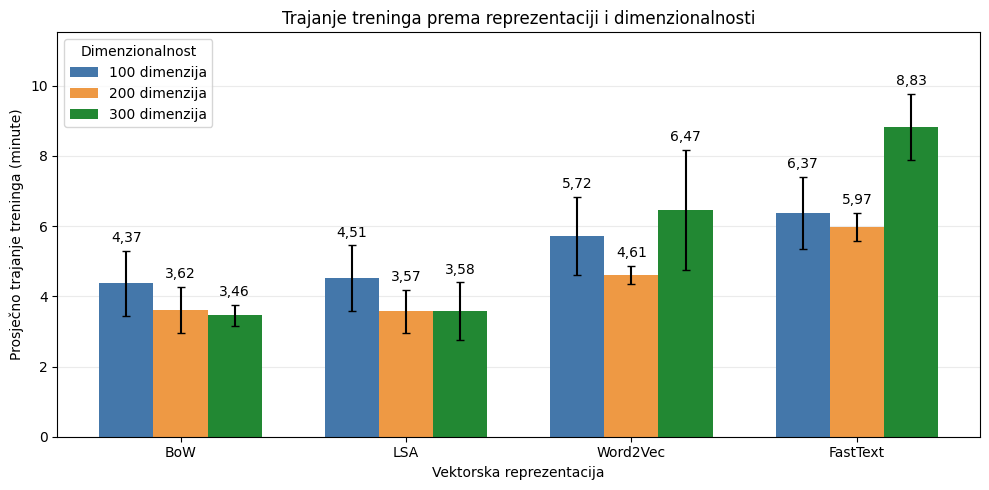

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


trajanje_sekunde = {
    tip: sazetak_konvergencije[sazetak_konvergencije["tip"] == tip]
        .sort_values("D")["trening_sekunde"].tolist()
    for tip in REPREZENTACIJE
}

reprezentacije = list(trajanje_sekunde)
dimenzije = [100, 200, 300]
vrijeme_minute = np.array(list(trajanje_sekunde.values())) / 60
odstupanja_minute = np.array([
    sazetak_konvergencije[sazetak_konvergencije["tip"] == tip]
    .sort_values("D")["trening_sekunde_SD"].to_numpy()
    for tip in reprezentacije
]) / 60

x = np.arange(len(reprezentacije))
sirina = 0.24
boje = ["#4477AA", "#EE9944", "#228833"]

fig, ax = plt.subplots(figsize=(10, 5))

for i, dimenzija in enumerate(dimenzije):
    stupci = ax.bar(
        x + (i - 1) * sirina,
        vrijeme_minute[:, i],
        width=sirina,
        yerr=odstupanja_minute[:, i],
        capsize=3,
        color=boje[i],
        label=f"{dimenzija} dimenzija"
    )

    oznake = [
        f"{vrijednost:.2f}".replace(".", ",")
        for vrijednost in vrijeme_minute[:, i]
    ]
    ax.bar_label(stupci, labels=oznake, padding=4, fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(reprezentacije)
ax.set_xlabel("Vektorska reprezentacija")
ax.set_ylabel("Prosječno trajanje treninga (minute)")
ax.set_title("Trajanje treninga prema reprezentaciji i dimenzionalnosti")
ax.set_ylim(0, (vrijeme_minute + odstupanja_minute).max() * 1.18)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Dimenzionalnost")

fig.tight_layout()
fig.savefig("trajanje_treninga.png", dpi=300, bbox_inches="tight")
plt.show()

Graf prikazuje prosječno trajanje pet treninga za svaku reprezentaciju i dimenzionalnost. Oznake odstupanja predstavljaju jednu standardnu devijaciju. Vrijeme obuhvaća izvođenje trening krugova.

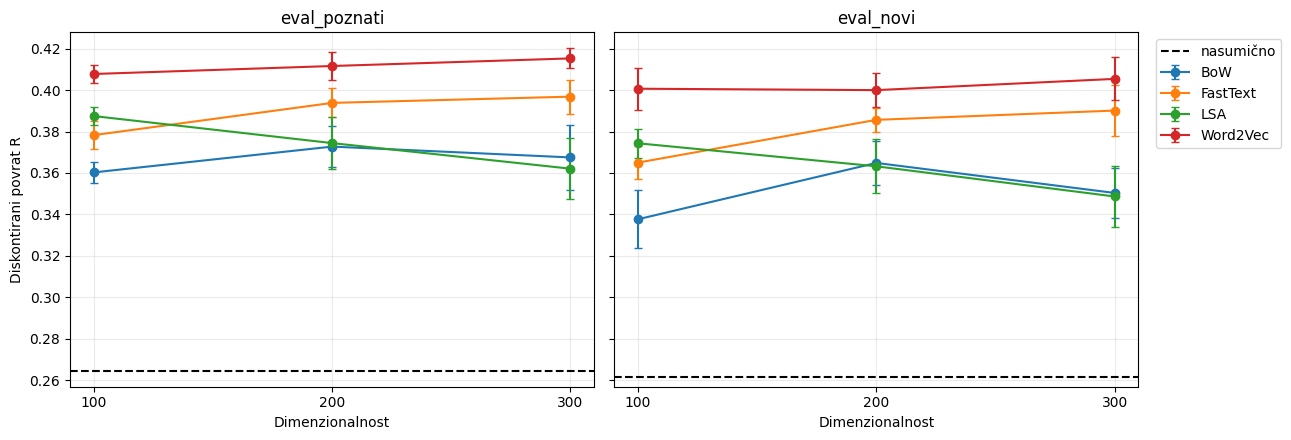

In [ ]:
fig, osi = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, skup in zip(osi, ["eval_poznati", "eval_novi"]):
    t = kvaliteta[kvaliteta["skup"] == skup]
    for tip, q in t.groupby("tip"):
        q = q.sort_values("D")
        ax.errorbar(q["D"], q["R"], yerr=q["R_SD"].fillna(0),
                    marker="o", capsize=3, label=tip)
    if len(t):
        ax.axhline(t["nasumicna_R"].iloc[0], color="black", linestyle="--", label="nasumično")
    ax.set_title(skup)
    ax.set_xlabel("Dimenzionalnost")
    ax.set_xticks(sorted(t["D"].unique()))
    ax.grid(alpha=0.25)
osi[0].set_ylabel("Diskontirani povrat R")
osi[1].legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Grafovi prikazuju povrat prema dimenzionalnosti za svaki tip vektora. Crte pogreške označavaju standardnu devijaciju između pet sjemena. Isprekidana linija prikazuje prosječni povrat nasumične politike na istom evaluacijskom skupu.

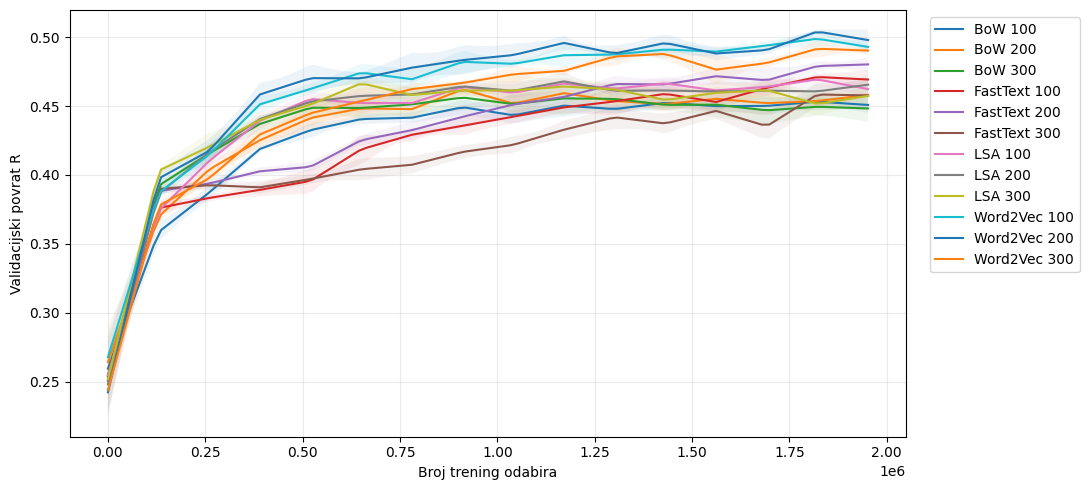

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
for (tip, d), t in krivulje_sve.groupby(["tip", "D"]):
    x = np.linspace(0, zajednicki_koraci, 101)
    linije = [np.interp(x, s.sort_values("koraci")["koraci"],
                       s.sort_values("koraci")["R"])
              for seed, s in t.groupby("seed")]
    y = np.asarray(linije)
    sredina = y.mean(0)
    sd = y.std(0, ddof=1) if len(y) > 1 else np.zeros_like(sredina)
    ax.plot(x, sredina, label=f"{tip} {d}")
    ax.fill_between(x, sredina - sd, sredina + sd, alpha=0.08)
ax.set_xlabel("Broj trening odabira")
ax.set_ylabel("Validacijski povrat R")
ax.legend(bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Na grafu je prikazano kako se validacijski povrat mijenja tijekom učenja za svih 12 kombinacija. Za svaku kombinaciju prikazan je prosjek pet sjemena, a zasjenjeni dio oko linije predstavlja standardnu devijaciju. Svi modeli prikazani su kroz jednak broj trening koraka kako bi se njihovi rezultati mogli usporediti.

In [ ]:
zavrsna_usporedba = kvaliteta.merge(
    sazetak_konvergencije, on=["tip", "D"], validate="many_to_one")
rezultati_po_epizodama = pd.concat(rezultati_epizoda, ignore_index=True)
postavke_pokusa = pd.DataFrame(konfiguracije_pokusa)
display(postotni_prikaz(zavrsna_usporedba))
display(postavke_pokusa[["tip", "D", "seed", "krug", "najbolji_krug",
    "koraci", "azuriranja", "trening_sekunde", "razlog_zavrsetka"]].round(3))
print("Dovršeno modela:", len(modeli_pokusa))

,tip,D,skup,Hit1,Hit2,Hit5,R,klikovi,odabiri,nDCG5,...,koraci_do_95,azuriranja_do_95,sekunde_do_95,trening_sekunde,AUC_R_SD,najbolji_val_R_SD,koraci_do_95_SD,azuriranja_do_95_SD,sekunde_do_95_SD,trening_sekunde_SD
0,BoW,100,eval_novi,8.9701,16.5838,34.1939,0.3377,0.3695,5.0,0.1843,...,650725.0,8128.0,58.4573,262.0128,0.0025,0.0034,159394.4213,1993.8847,13.6510,55.9447
1,BoW,100,eval_poznati,9.8337,17.6110,36.1365,0.3603,0.3944,5.0,0.1907,...,650725.0,8128.0,58.4573,262.0128,0.0025,0.0034,159394.4213,1993.8847,13.6510,55.9447
2,BoW,200,eval_novi,10.3171,18.0420,36.7743,0.3649,0.3988,5.0,0.2009,...,650725.0,8128.0,58.8265,217.1326,0.0020,0.0041,159394.4213,1993.8847,13.9220,38.9950
3,BoW,200,eval_poznati,10.2963,18.5376,36.9827,0.3727,0.4073,5.0,0.1984,...,650725.0,8128.0,58.8265,217.1326,0.0020,0.0041,159394.4213,1993.8847,13.9220,38.9950
4,BoW,300,eval_novi,10.2330,17.9192,35.1134,0.3504,0.3817,5.0,0.1944,...,520580.0,6500.0,48.4935,207.4282,0.0035,0.0049,92026.4120,1151.1698,8.3872,18.0528
5,BoW,300,eval_poznati,10.6825,18.5658,36.6867,0.3675,0.4009,5.0,0.1979,...,520580.0,6500.0,48.4935,207.4282,0.0035,0.0049,92026.4120,1151.1698,8.3872,18.0528
6,FastText,100,eval_novi,11.0424,19.0614,36.6836,0.3650,0.3974,5.0,0.2031,...,1613798.0,20175.2,137.2120,382.4927,0.0034,0.0061,174607.8402,2184.1912,13.6434,62.1669
7,FastText,100,eval_poznati,11.2036,19.7815,37.6246,0.3783,0.4117,5.0,0.2044,...,1613798.0,20175.2,137.2120,382.4927,0.0034,0.0061,174607.8402,2184.1912,13.6434,62.1669
8,FastText,200,eval_novi,12.0187,20.3788,38.3958,0.3857,0.4192,5.0,0.2154,...,1353508.0,16919.2,117.8958,358.2181,0.0032,0.0050,116405.2268,1456.1275,9.4243,24.3078
9,FastText,200,eval_poznati,12.1866,20.6526,38.8757,0.3938,0.4283,5.0,0.2129,...,1353508.0,16919.2,117.8958,358.2181,0.0032,0.0050,116405.2268,1456.1275,9.4243,24.3078


,tip,D,seed,krug,najbolji_krug,koraci,azuriranja,trening_sekunde,razlog_zavrsetka
0,BoW,100,7,26.0,16.0,3383770,42316,277.158,bez poboljšanja
1,BoW,100,18,19.0,9.0,2472755,30920,204.190,bez poboljšanja
2,BoW,100,39,24.0,14.0,3123480,39060,255.780,bez poboljšanja
3,BoW,100,64,33.0,23.0,4294785,53712,348.562,bez poboljšanja
4,BoW,100,91,21.0,11.0,2733045,34176,224.374,bez poboljšanja
5,BoW,200,7,25.0,15.0,3253625,40688,269.368,bez poboljšanja
6,BoW,200,18,18.0,8.0,2342610,29292,195.541,bez poboljšanja
7,BoW,200,39,23.0,13.0,2993335,37432,248.348,bez poboljšanja
8,BoW,200,64,17.0,7.0,2212465,27664,186.128,bez poboljšanja
9,BoW,200,91,17.0,7.0,2212465,27664,186.278,bez poboljšanja


Dovršeno modela: 60


Završna tablica objedinjuje kvalitetu preporuka, tijek učenja i potrošeno vrijeme. Prikazuje se i razlog završetka svakog treninga.

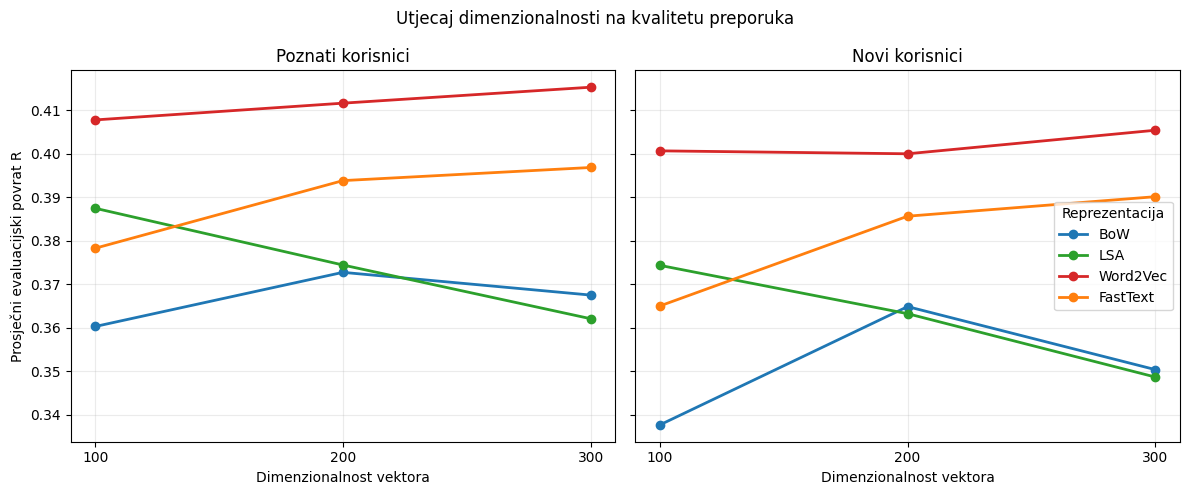

In [ ]:
import matplotlib.pyplot as plt

dimenzije = [100, 200, 300]

povrati = {
    naziv: {
        tip: kvaliteta[(kvaliteta["skup"] == skup) & (kvaliteta["tip"] == tip)]
            .sort_values("D")["R"].tolist()
        for tip in REPREZENTACIJE
    }
    for naziv, skup in [("Poznati korisnici", "eval_poznati"),
                        ("Novi korisnici", "eval_novi")]
}

boje = {
    "BoW": "tab:blue",
    "LSA": "tab:green",
    "Word2Vec": "tab:red",
    "FastText": "tab:orange",
}

fig, osi = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for os, (skup, reprezentacije) in zip(osi, povrati.items()):
    for tip, vrijednosti in reprezentacije.items():
        os.plot(
            dimenzije, vrijednosti,
            marker="o", linewidth=2,
            color=boje[tip], label=tip
        )

    os.set_title(skup)
    os.set_xlabel("Dimenzionalnost vektora")
    os.set_xticks(dimenzije)
    os.grid(alpha=0.25)

osi[0].set_ylabel("Prosječni evaluacijski povrat R")
osi[1].legend(title="Reprezentacija")
fig.suptitle("Utjecaj dimenzionalnosti na kvalitetu preporuka")

plt.tight_layout()
plt.show()

Na grafovima se uspoređuje prosječni evaluacijski povrat DQN-a za sve četiri vrste vektorskih reprezentacija u dimenzijama 100, 200 i 300. Rezultati su posebno prikazani za poznate i nove korisnike. Word2Vec s 300 dimenzija ostvaruje najveći prosječni povrat na obje skupine korisnika. Kod FastTexta prosječni povrat raste povećanjem dimenzionalnosti, kod BoW-a najveći je s 200 dimenzija, a kod LSA-e sa 100 dimenzija. Graf prikazuje prosjeke pet treninga, dok su standardne devijacije prikazane u prethodnoj usporedbi.

In [ ]:
#Dodatne analize i grafovi

In [ ]:
cs = segmenti[segmenti["segment"] == "cold-start"].copy()
cs["razlika_Hit5_pp"] = 100 * (cs["Hit5"] - cs["Hit5_kosinusna"])
cs["razlika_R"] = cs["R"] - cs["R_kosinusna"]
print(cs[["tip", "D", "skup", "korisnici", "Hit5", "Hit5_kosinusna",
          "razlika_Hit5_pp", "R", "R_kosinusna", "razlika_R"]]
      .round(4).to_string())
print("DQN bolji po R u", (cs["razlika_R"] > 0).sum(), "od", len(cs), "redaka")

         tip    D          skup  korisnici    Hit5  Hit5_kosinusna  razlika_Hit5_pp       R  R_kosinusna  razlika_R
0        BoW  100     eval_novi         91  0.3285          0.2396           8.8938  0.3191       0.2292     0.0899
3        BoW  100  eval_poznati         95  0.2870          0.2930          -0.5965  0.2837       0.2877    -0.0040
6        BoW  200     eval_novi         91  0.3103          0.2795           3.0842  0.3124       0.2788     0.0336
9        BoW  200  eval_poznati         95  0.2923          0.2947          -0.2456  0.2858       0.3152    -0.0294
12       BoW  300     eval_novi         91  0.3256          0.2731           5.2527  0.3144       0.2748     0.0397
15       BoW  300  eval_poznati         95  0.2830          0.2956          -1.2632  0.2753       0.2962    -0.0209
18  FastText  100     eval_novi         91  0.3289          0.2601           6.8828  0.3185       0.2572     0.0612
21  FastText  100  eval_poznati         95  0.2809          0.2895      

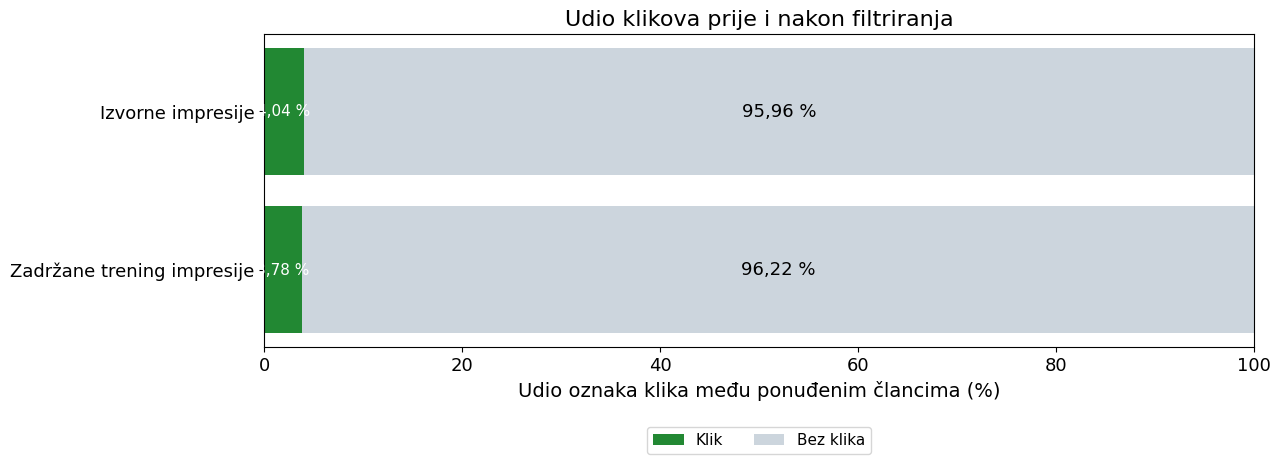

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

boje_reprezentacija = {
    "BoW": "#4477AA",
    "LSA": "#228833",
    "Word2Vec": "#AA3377",
    "FastText": "#CC8811"
}

boje_dimenzija = {
    100: "#4477AA",
    200: "#EE7733",
    300: "#228833"
}

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "legend.fontsize": 11
})

broj_klikova = behaviors["Impressions"].fillna("").str.count(r"-1(?=\s|$)").sum()
broj_neklikova = behaviors["Impressions"].fillna("").str.count(r"-0(?=\s|$)").sum()

klikovi_treninga = sum(float(y.sum()) for a, y in trening_epizode)
prikazi_treninga = sum(len(y) for a, y in trening_epizode)

udjeli = 100 * np.array([
    broj_klikova / (broj_klikova + broj_neklikova),
    klikovi_treninga / prikazi_treninga
])

fig, ax = plt.subplots(figsize=(13, 5))
oznake = ["Izvorne impresije", "Zadržane trening impresije"]

ax.barh(oznake, udjeli, color="#228833", label="Klik")
ax.barh(
    oznake, 100 - udjeli, left=udjeli,
    color="#CCD5DD", label="Bez klika"
)

for i, udio in enumerate(udjeli):
    ax.text(
        udio / 2, i,
        f"{udio:.2f} %".replace(".", ","),
        ha="center", va="center", color="white", fontsize=11
    )
    ax.text(
        udio + (100 - udio) / 2, i,
        f"{100 - udio:.2f} %".replace(".", ","),
        ha="center", va="center"
    )

ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("Udio oznaka klika među ponuđenim člancima (%)")
ax.set_title("Udio klikova prije i nakon filtriranja")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.23), ncol=2)

fig.tight_layout()
plt.show()

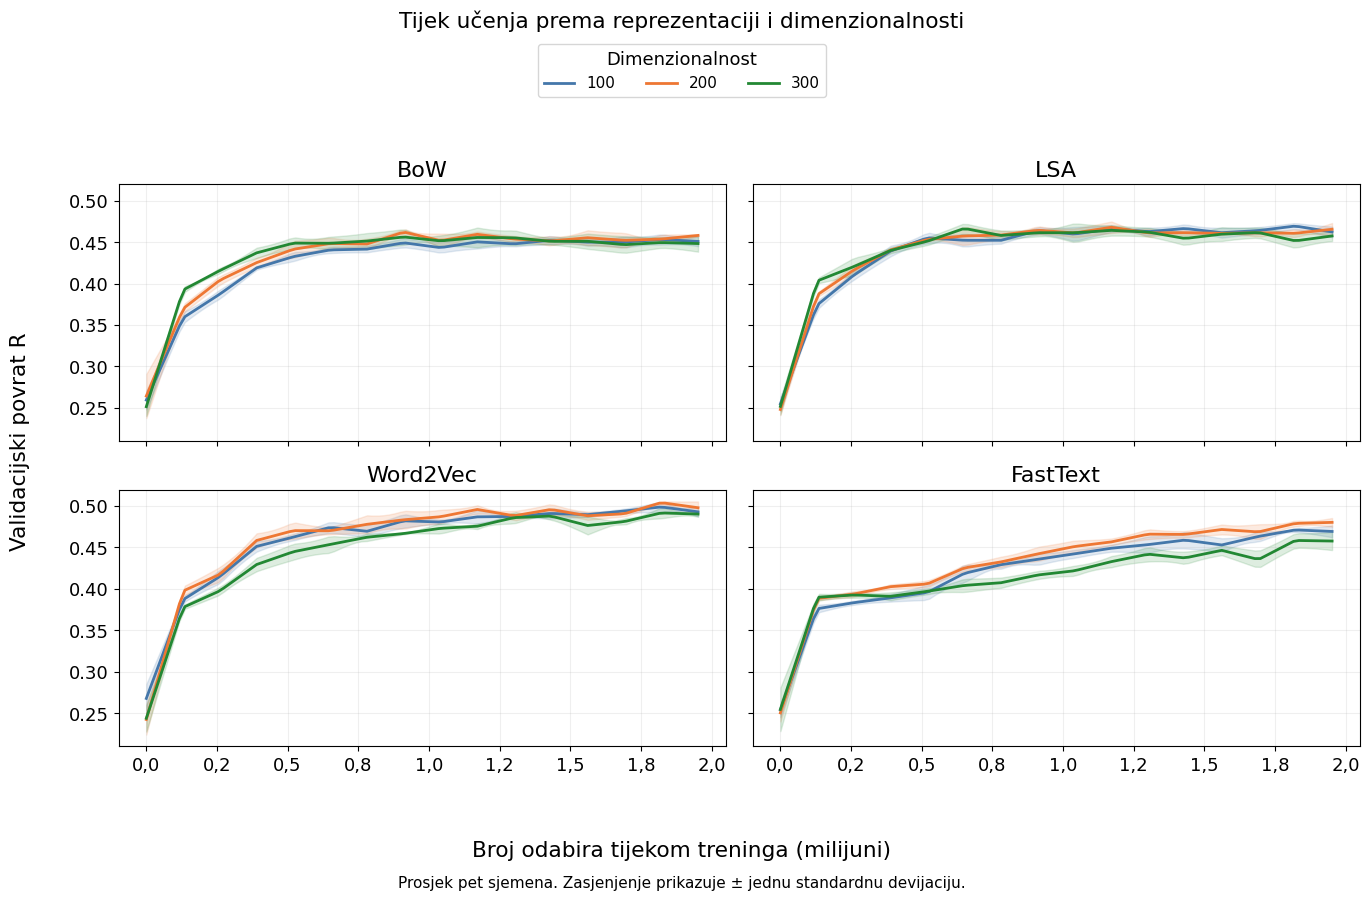

In [ ]:
fig, osi = plt.subplots(
    2, 2, figsize=(14, 9), sharex=True, sharey=True
)

raspon = np.linspace(0, zajednicki_koraci, 101)

for ax, tip in zip(osi.flat, boje_reprezentacija):
    for dimenzija, boja in boje_dimenzija.items():
        dio = krivulje_sve[
            (krivulje_sve["tip"] == tip) &
            (krivulje_sve["D"] == dimenzija)
        ]

        linije = []
        for seed, zapis in dio.groupby("seed"):
            zapis = (
                zapis.sort_values("koraci")
                .drop_duplicates("koraci", keep="last")
            )
            linije.append(
                np.interp(raspon, zapis["koraci"], zapis["R"])
            )

        linije = np.asarray(linije)
        sredina = linije.mean(axis=0)
        odstupanje = linije.std(axis=0, ddof=1)

        ax.plot(
            raspon / 1e6, sredina,
            color=boja, label=str(dimenzija), linewidth=2
        )
        ax.fill_between(
            raspon / 1e6,
            sredina - odstupanje,
            sredina + odstupanje,
            color=boja, alpha=0.15
        )

    ax.set_title(tip)
    ax.grid(alpha=0.2)
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, p: f"{x:.1f}".replace(".", ","))
    )

fig.suptitle("Tijek učenja prema reprezentaciji i dimenzionalnosti")
fig.supxlabel("Broj odabira tijekom treninga (milijuni)", y=0.035)
fig.supylabel("Validacijski povrat R")

oznake_legende, tekst_legende = osi[0, 0].get_legend_handles_labels()
fig.legend(
    oznake_legende, tekst_legende,
    title="Dimenzionalnost",
    loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=3
)

fig.text(
    0.5, 0.005,
    "Prosjek pet sjemena. Zasjenjenje prikazuje ± jednu standardnu devijaciju.",
    ha="center", fontsize=11
)

fig.tight_layout(rect=(0.02, 0.065, 1, 0.88))
plt.show()

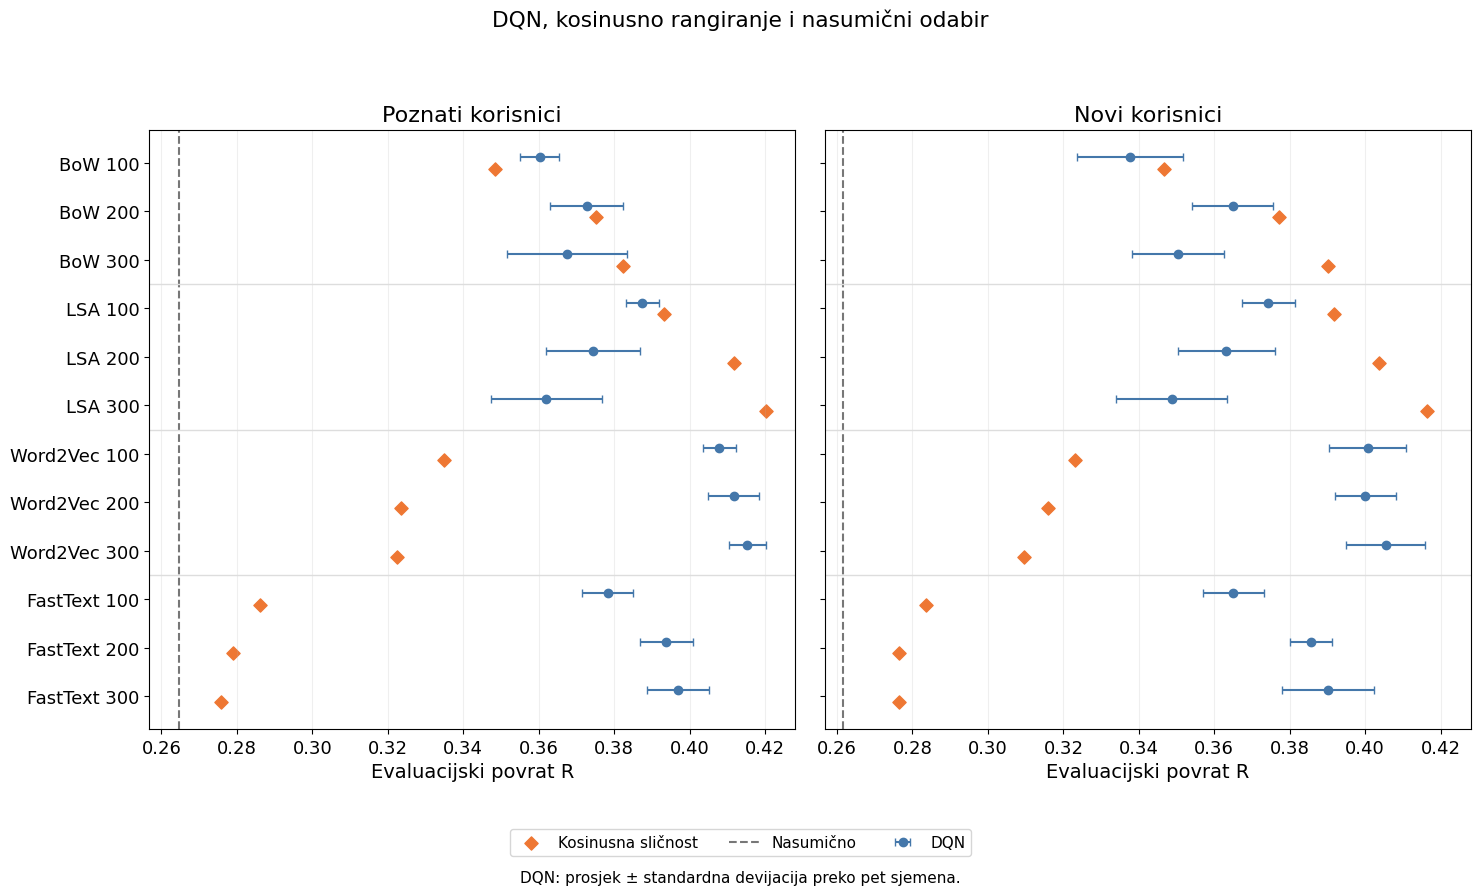

In [ ]:
redoslijed_grafa = [
    (tip, d)
    for tip in boje_reprezentacija
    for d in [100, 200, 300]
]

fig, osi = plt.subplots(
    1, 2, figsize=(15, 9), sharex=True, sharey=True
)

mjesta = np.arange(len(redoslijed_grafa))

for ax, skup, naslov in zip(
    osi,
    ["eval_poznati", "eval_novi"],
    ["Poznati korisnici", "Novi korisnici"]
):
    dio = (
        kvaliteta[kvaliteta["skup"] == skup]
        .set_index(["tip", "D"])
        .reindex(
            pd.MultiIndex.from_tuples(
                redoslijed_grafa, names=["tip", "D"]
            )
        )
    )

    ax.errorbar(
        dio["R"], mjesta - 0.12,
        xerr=dio["R_SD"],
        fmt="o", color="#4477AA", capsize=3, label="DQN"
    )
    ax.scatter(
        dio["kosinusna_R"], mjesta + 0.12,
        color="#EE7733", marker="D", s=45,
        label="Kosinusna sličnost"
    )
    ax.axvline(
        dio["nasumicna_R"].iloc[0],
        color="#777777", linestyle="--", label="Nasumično"
    )

    for granica in [2.5, 5.5, 8.5]:
        ax.axhline(granica, color="#DDDDDD", linewidth=1)

    ax.set_title(naslov)
    ax.set_xlabel("Evaluacijski povrat R")
    ax.set_yticks(
        mjesta,
        [f"{tip} {d}" for tip, d in redoslijed_grafa]
    )
    ax.grid(axis="x", alpha=0.2)

osi[0].invert_yaxis()

oznake_legende, tekst_legende = osi[0].get_legend_handles_labels()
fig.legend(
    oznake_legende, tekst_legende,
    loc="lower center", bbox_to_anchor=(0.5, 0.03), ncol=3
)

fig.suptitle("DQN, kosinusno rangiranje i nasumični odabir")
fig.text(
    0.5, 0.01,
    "DQN: prosjek ± standardna devijacija preko pet sjemena.",
    ha="center", fontsize=11
)

fig.tight_layout(rect=(0, 0.1, 1, 0.94))
plt.show()

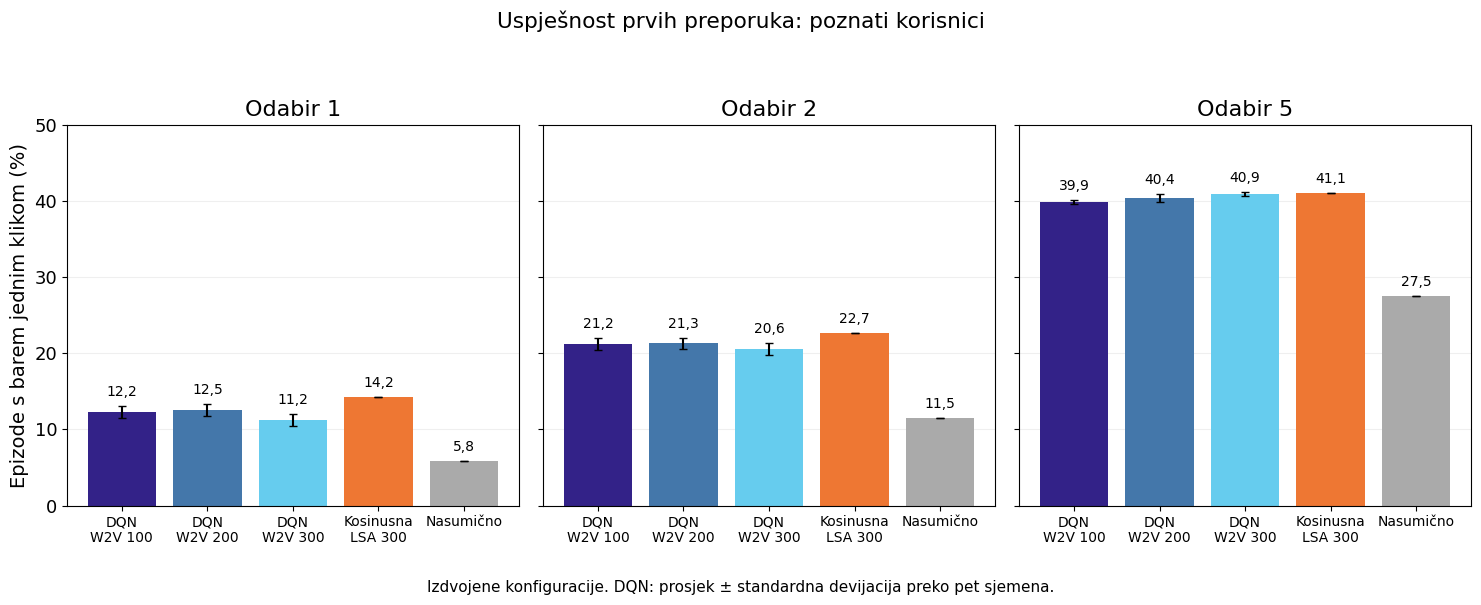

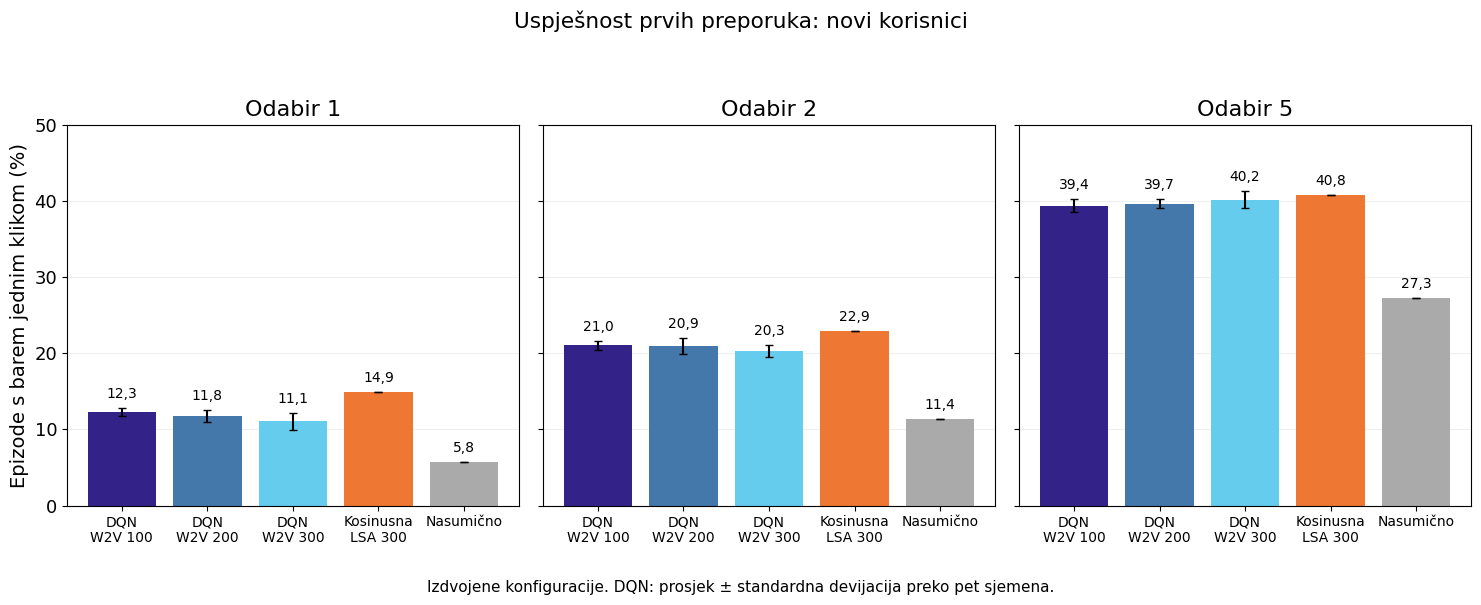

In [ ]:
for skup, naslov in [
    ("eval_poznati", "Poznati korisnici"),
    ("eval_novi", "Novi korisnici")
]:
    dio = (
        kvaliteta[kvaliteta["skup"] == skup]
        .set_index(["tip", "D"])
    )

    fig, osi = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

    nazivi = [
        "DQN\nW2V 100",
        "DQN\nW2V 200",
        "DQN\nW2V 300",
        "Kosinusna\nLSA 300",
        "Nasumično"
    ]
    boje = ["#332288", "#4477AA", "#66CCEE", "#EE7733", "#AAAAAA"]

    for ax, metrika, oznaka in zip(
        osi,
        ["Hit1", "Hit2", "Hit5"],
        ["Odabir 1", "Odabir 2", "Odabir 5"]
    ):
        vrijednosti = [
            100 * dio.loc[("Word2Vec", d), metrika]
            for d in [100, 200, 300]
        ]
        vrijednosti += [
            100 * dio.loc[("LSA", 300), "kosinusna_" + metrika],
            100 * dio.iloc[0]["nasumicna_" + metrika]
        ]

        odstupanja = [
            100 * dio.loc[("Word2Vec", d), metrika + "_SD"]
            for d in [100, 200, 300]
        ] + [0, 0]

        stupci = ax.bar(
            np.arange(5), vrijednosti,
            yerr=odstupanja, capsize=3, color=boje
        )
        ax.bar_label(
            stupci,
            labels=[f"{v:.1f}".replace(".", ",") for v in vrijednosti],
            padding=5, fontsize=10
        )

        ax.set_xticks(np.arange(5), nazivi, fontsize=10)
        ax.set_title(oznaka)
        ax.set_ylim(0, 50)
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)

    osi[0].set_ylabel("Epizode s barem jednim klikom (%)")
    fig.suptitle(f"Uspješnost prvih preporuka: {naslov.lower()}")
    fig.text(
        0.5, 0.01,
        "Izdvojene konfiguracije. DQN: prosjek ± standardna devijacija preko pet sjemena.",
        ha="center", fontsize=11
    )

    fig.tight_layout(rect=(0, 0.055, 1, 0.93))
    plt.show()

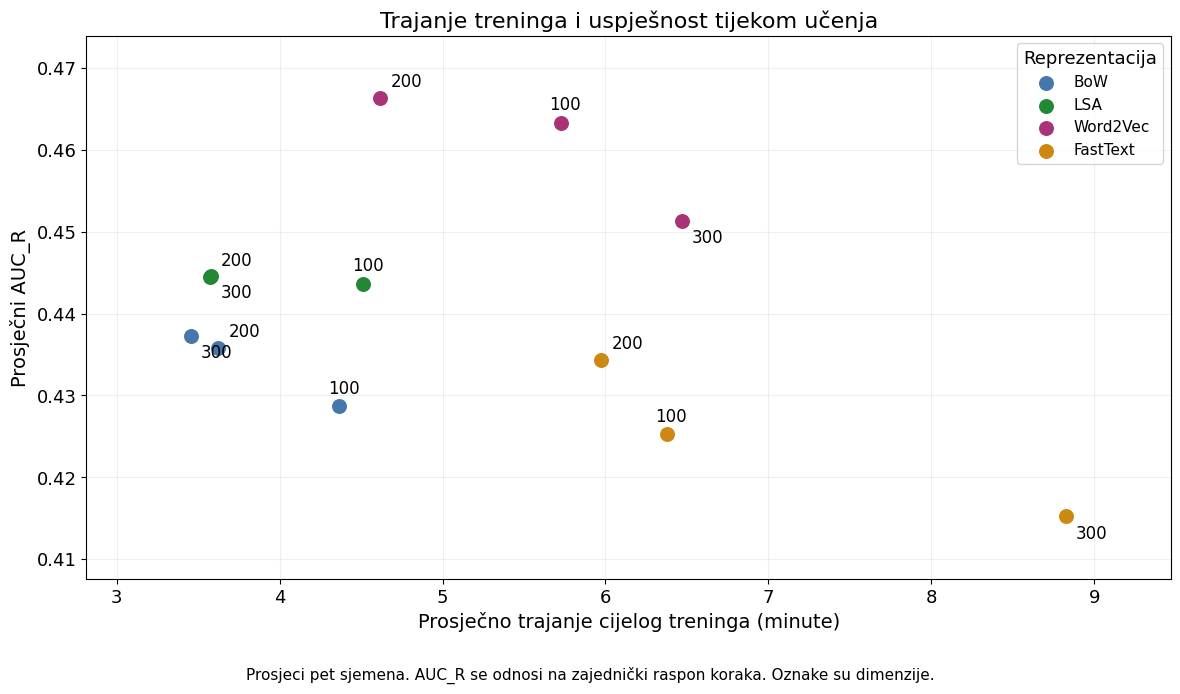

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))

pomaci = {
    100: (-8, 9),
    200: (8, 8),
    300: (7, -16)
}

for tip, boja in boje_reprezentacija.items():
    dio = sazetak_konvergencije[
        sazetak_konvergencije["tip"] == tip
    ]

    ax.scatter(
        dio["trening_sekunde"] / 60,
        dio["AUC_R"],
        color=boja, s=95, label=tip
    )

    for _, red in dio.iterrows():
        dimenzija = int(red["D"])
        ax.annotate(
            str(dimenzija),
            (red["trening_sekunde"] / 60, red["AUC_R"]),
            xytext=pomaci[dimenzija],
            textcoords="offset points",
            fontsize=12
        )

ax.set_xlabel("Prosječno trajanje cijelog treninga (minute)")
ax.set_ylabel("Prosječni AUC_R")
ax.set_title("Trajanje treninga i uspješnost tijekom učenja")
ax.legend(title="Reprezentacija")
ax.grid(alpha=0.2)
ax.margins(x=0.12, y=0.15)

fig.text(
    0.5, 0.015,
    "Prosjeci pet sjemena. AUC_R se odnosi na zajednički raspon koraka. Oznake su dimenzije.",
    ha="center", fontsize=11
)

fig.tight_layout(rect=(0, 0.055, 1, 1))
plt.show()

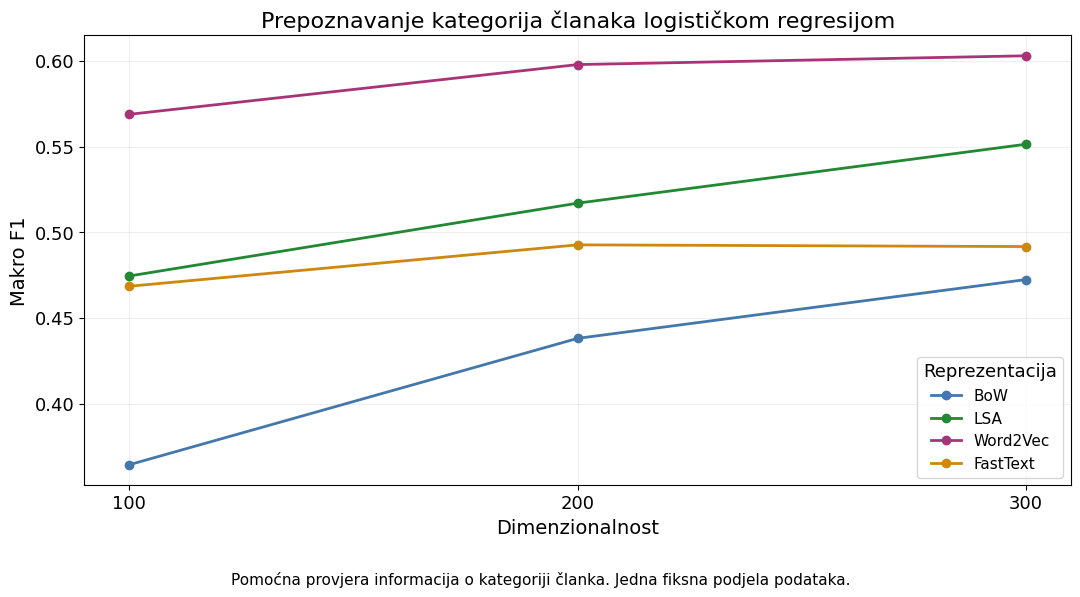

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))

for tip, boja in boje_reprezentacija.items():
    dio = rezultati_df[
        rezultati_df["tip"] == tip
    ].sort_values("D")

    ax.plot(
        dio["D"], dio["macro_f1"],
        color=boja, marker="o", linewidth=2, label=tip
    )

ax.set_xticks([100, 200, 300])
ax.set_xlabel("Dimenzionalnost")
ax.set_ylabel("Makro F1")
ax.set_title("Prepoznavanje kategorija članaka logističkom regresijom")
ax.legend(title="Reprezentacija")
ax.grid(alpha=0.2)

fig.text(
    0.5, 0.01,
    "Pomoćna provjera informacija o kategoriji članka. Jedna fiksna podjela podataka.",
    ha="center", fontsize=11
)

fig.tight_layout(rect=(0, 0.055, 1, 1))
plt.show()

In [ ]:
skupovi_jaza = ["validacija", "eval_poznati", "eval_novi"]

dqn_jaz = rezultati_svi.loc[
    (rezultati_svi["segment"] == "svi") &
    rezultati_svi["skup"].isin(skupovi_jaza),
    ["tip", "D", "seed", "skup", "R"]
].copy()
dqn_jaz["politika"] = "DQN"

kosinusna_jaz = kosinusna_sve.loc[
    (kosinusna_sve["segment"] == "svi") &
    kosinusna_sve["skup"].isin(skupovi_jaza),
    ["tip", "D", "skup", "R"]
].copy()
kosinusna_jaz["politika"] = "Kosinusna"
kosinusna_jaz["seed"] = -1

usporedba_jaza = pd.concat(
    [dqn_jaz, kosinusna_jaz],
    ignore_index=True
)

nasumicna_jaz = reference_sve.loc[
    (reference_sve["segment"] == "svi") &
    reference_sve["skup"].isin(skupovi_jaza),
    ["tip", "D", "skup", "R"]
].rename(columns={"R": "nasumicna_R"})

usporedba_jaza = usporedba_jaza.merge(
    nasumicna_jaz,
    on=["tip", "D", "skup"],
    validate="many_to_one"
)

usporedba_jaza["dobit_R"] = (
    usporedba_jaza["R"] - usporedba_jaza["nasumicna_R"]
)

kljucevi_jaza = ["tip", "D", "politika", "seed"]

validacija_jaza = usporedba_jaza.loc[
    usporedba_jaza["skup"] == "validacija",
    kljucevi_jaza + ["R", "dobit_R"]
].rename(columns={
    "R": "R_validacija",
    "dobit_R": "dobit_validacija"
})

test_jaza = usporedba_jaza.loc[
    usporedba_jaza["skup"].isin(["eval_poznati", "eval_novi"])
].rename(columns={
    "R": "R_test",
    "dobit_R": "dobit_test"
})

jaz_po_sjemenu = test_jaza.merge(
    validacija_jaza,
    on=kljucevi_jaza,
    validate="many_to_one"
)

jaz_po_sjemenu["jaz_R"] = (
    jaz_po_sjemenu["R_validacija"] - jaz_po_sjemenu["R_test"]
)
jaz_po_sjemenu["jaz_dobiti"] = (
    jaz_po_sjemenu["dobit_validacija"] - jaz_po_sjemenu["dobit_test"]
)

sazetak_jaza = jaz_po_sjemenu.groupby(
    ["tip", "D", "politika", "skup"]
).agg(
    R_validacija=("R_validacija", "mean"),
    R_test=("R_test", "mean"),
    jaz_R=("jaz_R", "mean"),
    jaz_R_SD=("jaz_R", "std"),
    dobit_validacija=("dobit_validacija", "mean"),
    dobit_test=("dobit_test", "mean"),
    jaz_dobiti=("jaz_dobiti", "mean")
).reset_index()

for skup, naziv in [
    ("eval_poznati", "Validacija prema poznatim korisnicima"),
    ("eval_novi", "Validacija prema novim korisnicima")
]:
    print(naziv)
    prikaz_jaza = (
        sazetak_jaza[sazetak_jaza["skup"] == skup]
        .drop(columns="skup")
        .sort_values(["tip", "D", "politika"])
    )
    display(prikaz_jaza.round(4))

Validacija prema poznatim korisnicima


,tip,D,politika,R_validacija,R_test,jaz_R,jaz_R_SD,dobit_validacija,dobit_test,jaz_dobiti
1,BoW,100,DQN,0.4574,0.3603,0.0971,0.0045,0.2007,0.0957,0.1050
3,BoW,100,Kosinusna,0.3612,0.3485,0.0127,NaN,0.1045,0.0839,0.0206
5,BoW,200,DQN,0.4644,0.3727,0.0916,0.0087,0.2077,0.1082,0.0995
7,BoW,200,Kosinusna,0.3593,0.3752,-0.0159,NaN,0.1026,0.1106,-0.0080
9,BoW,300,DQN,0.4630,0.3675,0.0955,0.0166,0.2063,0.1029,0.1034
11,BoW,300,Kosinusna,0.3646,0.3823,-0.0177,NaN,0.1079,0.1177,-0.0098
13,FastText,100,DQN,0.4870,0.3783,0.1087,0.0065,0.2303,0.1137,0.1166
15,FastText,100,Kosinusna,0.2759,0.2861,-0.0103,NaN,0.0192,0.0216,-0.0024
17,FastText,200,DQN,0.4911,0.3938,0.0973,0.0032,0.2344,0.1293,0.1052
19,FastText,200,Kosinusna,0.2710,0.2789,-0.0080,NaN,0.0143,0.0144,-0.0001


Validacija prema novim korisnicima


,tip,D,politika,R_validacija,R_test,jaz_R,jaz_R_SD,dobit_validacija,dobit_test,jaz_dobiti
0,BoW,100,DQN,0.4574,0.3377,0.1197,0.0160,0.2007,0.0761,0.1245
2,BoW,100,Kosinusna,0.3612,0.3466,0.0146,NaN,0.1045,0.0850,0.0195
4,BoW,200,DQN,0.4644,0.3649,0.0995,0.0090,0.2077,0.1033,0.1044
6,BoW,200,Kosinusna,0.3593,0.3772,-0.0179,NaN,0.1026,0.1157,-0.0131
8,BoW,300,DQN,0.4630,0.3504,0.1126,0.0142,0.2063,0.0889,0.1175
10,BoW,300,Kosinusna,0.3646,0.3901,-0.0255,NaN,0.1079,0.1286,-0.0207
12,FastText,100,DQN,0.4870,0.3650,0.1220,0.0067,0.2303,0.1035,0.1268
14,FastText,100,Kosinusna,0.2759,0.2835,-0.0076,NaN,0.0192,0.0220,-0.0028
16,FastText,200,DQN,0.4911,0.3857,0.1055,0.0046,0.2344,0.1241,0.1103
18,FastText,200,Kosinusna,0.2710,0.2764,-0.0054,NaN,0.0143,0.0149,-0.0006
